## Marketing Insights For E-Commerce Company

## 1. Business Problem:

### Business Context:
One of the leading E-Commerce Company would like to get marketing insights from the data to define marketing strategies going forward. Also, expecting to build an analytical dashboard to monitor various KPI’s & business metrics.

### Business Objective:
The e-commerce company is expecting analysis using the data, the details are mentioned along with individual analysis

## 2. Data Information:

### 1. Data Dictionary:
Transaction data has been provided for the period of 1st Jan 2019 to 31st Dec 2019. The below data sets have been provided.

**Online_Sales.csv**: This file contains actual orders data (point of Sales data) at transaction level. It has information on the transactions such as Customer ID, transaction details such as ID and date, product details such as category. It also has coupon status, delivery charges included in the transaction

**Customers_Data.csv**: This file contains customer’s demographics. It includes ID, location, gender etc

**Discount_Coupon.csv**: This file contains the Discount coupon details, such as Code, percentage, product category and month

**Marketing_Spend.csv**: This file incudes the marketing spend on both offline & online channels date-wise

**Tax_Amount.csv**: GST Details for a given category

### 2. Key Definitions:

**Invoice Value: Invoice Value** =(( Quantity*Avg_price)*(1-Dicount_pct)*(1+GST))+Delivery_Charges

**Average order value** = Revenue / Transaction per customer

**Profit Margin** Profit margin is the commonly used profitability ratio. It represents how much percentage of total sales has earned as the gain.

**Purchase Frequency** is the average number of purchases made by a customer over a defined period of time (typically one month or one year). It is the sum of total number transactions divided by total number customers.

**Repeat rate** shows you the percentage of your current customer base that has come back to shop again.

**Churn Rate** is the annual percentage rate at which customers stop subscribing.

**Customer lifetime value**, lifetime customer value, or life-time value is a prediction of the net profit/revenue attributed to the entire future relationship with a customer.

## 3. Importing Libraries

All the necessary libraries like Pandas, Numpy to perform the operations. Libraries Matplotlib and Seaborn are used for Visualization. 


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as datetime

## 4. Preprocessing

### 1. Data Loading

Import the case study files including 3 .csv files. 

In [2]:
input_path = ".../Finding-Marketing-Insights//Datasets//"

Online_Sales_DF = pd.read_csv(input_path+"Online_Sales.csv")
Customers_Data_DF = pd.read_excel( input_path+"CustomersData.xlsx")
Discount_Coupon_DF = pd.read_csv( input_path+"Discount_Coupon.csv")
Marketing_Spend_DF = pd.read_csv( input_path+"Marketing_Spend.csv")
Tax_Amount_DF =  pd.read_excel( input_path+"Tax_amount.xlsx")

### 2. Data exploration

#### Online Sales DF

In [3]:
print(f"Online Sales DF first 5 rows:\n")
print(Online_Sales_DF.head())
print("\n\n")
print(f"Online Sales DF shape:\n")
print(Online_Sales_DF.shape)
print("\n\n")
print(f"Online Sales DF info:\n")
print(Online_Sales_DF.info())
print("\n\n")      
print(f"Online Sales DF statistical parameters:\n")
print(Online_Sales_DF.describe())


Online Sales DF first 5 rows:

   CustomerID  Transaction_ID  Transaction_Date     Product_SKU  \
0       17850           16679          20190101  GGOENEBJ079499   
1       17850           16680          20190101  GGOENEBJ079499   
2       17850           16681          20190101  GGOEGFKQ020399   
3       17850           16682          20190101  GGOEGAAB010516   
4       17850           16682          20190101  GGOEGBJL013999   

                                 Product_Description Product_Category  \
0  Nest Learning Thermostat 3rd Gen-USA - Stainle...         Nest-USA   
1  Nest Learning Thermostat 3rd Gen-USA - Stainle...         Nest-USA   
2              Google Laptop and Cell Phone Stickers           Office   
3  Google Men's 100% Cotton Short Sleeve Hero Tee...          Apparel   
4                    Google Canvas Tote Natural/Navy             Bags   

   Quantity  Avg_Price  Delivery_Charges Coupon_Status  
0         1     153.71               6.5          Used  
1         1  

In [4]:
## From the above, we can make the following observations:
# 1. The Transaction_Date column is not in Datetime format
# 2. There are 52924 rows and 10 columns in the DataFrame. 
# 3. There are no missing values in any of the columns

Online_Sales_DF['Transaction_Date'] =pd.to_datetime(Online_Sales_DF['Transaction_Date'],format='%Y%m%d')

# Creating a new column 'Transaction Month'
Online_Sales_DF['Transaction_Month'] = Online_Sales_DF['Transaction_Date'].dt.strftime('%b')


In [5]:
Online_Sales_DF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52924 entries, 0 to 52923
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   CustomerID           52924 non-null  int64         
 1   Transaction_ID       52924 non-null  int64         
 2   Transaction_Date     52924 non-null  datetime64[ns]
 3   Product_SKU          52924 non-null  object        
 4   Product_Description  52924 non-null  object        
 5   Product_Category     52924 non-null  object        
 6   Quantity             52924 non-null  int64         
 7   Avg_Price            52924 non-null  float64       
 8   Delivery_Charges     52924 non-null  float64       
 9   Coupon_Status        52924 non-null  object        
 10  Transaction_Month    52924 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(5)
memory usage: 4.4+ MB


In [6]:
Online_Sales_DF['Transaction_Month'].sample(5)

22957    Jun
9289     Mar
8386     Mar
40686    Oct
22846    Jun
Name: Transaction_Month, dtype: object

#### Customers Data DF 

In [7]:
print(f"Customers Data DF first 5 rows:\n")
print(Customers_Data_DF.head())
print("\n\n")
print(f"Customers Data DF shape:\n")
print(Customers_Data_DF.shape)
print("\n\n")
print(f"Customers Data DF info:\n")
print(Customers_Data_DF.info())
print("\n\n")      
print(f"Customers Data DF statistical parameters:\n")
print(Customers_Data_DF.describe())

Customers Data DF first 5 rows:

   CustomerID Gender    Location  Tenure_Months
0       17850      M     Chicago             12
1       13047      M  California             43
2       12583      M     Chicago             33
3       13748      F  California             30
4       15100      M  California             49



Customers Data DF shape:

(1468, 4)



Customers Data DF info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1468 entries, 0 to 1467
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerID     1468 non-null   int64 
 1   Gender         1468 non-null   object
 2   Location       1468 non-null   object
 3   Tenure_Months  1468 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 46.0+ KB
None



Customers Data DF statistical parameters:

         CustomerID  Tenure_Months
count   1468.000000    1468.000000
mean   15314.386240      25.912125
std     1744.000367      13.959667
min   

In [8]:
# ### From the above, we can draw the following observations:
# 1. All columns are in the expected datatype
# 2. The Dataframe has 1468 rows an 4 columns
# 3. There are no null values in any of the columns


#### Discount Coupon DF

In [9]:
print(f"Discount Coupon DF first 5 rows:\n")
print(Discount_Coupon_DF.head())
print("\n\n")
print(f"Discount Coupon DF shape:\n")
print(Discount_Coupon_DF.shape)
print("\n\n")
print(f"Discount Coupon DF info:\n")
print(Discount_Coupon_DF.info())
print("\n\n")      
print(f"Discount Coupon DF statistical parameters:\n")
print(Discount_Coupon_DF.describe())

Discount Coupon DF first 5 rows:

  Month Product_Category  Coupon_Code  Discount_pct
0   Jan           Apparel      SALE10            10
1   Feb           Apparel      SALE20            20
2   Mar           Apparel      SALE30            30
3   Jan          Nest-USA      ELEC10            10
4   Feb          Nest-USA      ELEC20            20



Discount Coupon DF shape:

(204, 4)



Discount Coupon DF info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Month              204 non-null    object
 1   Product_Category   204 non-null    object
 2   Coupon_Code        204 non-null    object
 3   Discount_pct       204 non-null    int64 
dtypes: int64(1), object(3)
memory usage: 6.5+ KB
None



Discount Coupon DF statistical parameters:

       Discount_pct
count    204.000000
mean      20.000000
std        8.185052
min       10.00000

In [10]:
## From the above, we can make the following observations about Discount Coupon DF:

# 1. All the columns are in the expected data type
# 2. The dataframe has 204 rows and 4 columns
# 3. THere are no null values in any of the columns

#### Marketing Spend DF

In [11]:
print(f"Marketing Spend DF first 5 rows:\n")
print(Marketing_Spend_DF.head())
print("\n\n")
print(f"Marketing Spend DF shape:\n")
print(Marketing_Spend_DF.shape)
print("\n\n")
print(f"Marketing Spend DF info:\n")
print(Marketing_Spend_DF.info())
print("\n\n")      
print(f"Marketing Spend DF statistical parameters:\n")
print(Marketing_Spend_DF.describe())

Marketing Spend DF first 5 rows:

       Date  Offline_Spend  Online_Spend
0  1/1/2019           4500       2424.50
1  1/2/2019           4500       3480.36
2  1/3/2019           4500       1576.38
3  1/4/2019           4500       2928.55
4  1/5/2019           4500       4055.30



Marketing Spend DF shape:

(365, 3)



Marketing Spend DF info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           365 non-null    object 
 1   Offline_Spend  365 non-null    int64  
 2   Online_Spend   365 non-null    float64
dtypes: float64(1), int64(1), object(1)
memory usage: 8.7+ KB
None



Marketing Spend DF statistical parameters:

       Offline_Spend  Online_Spend
count     365.000000    365.000000
mean     2843.561644   1905.880740
std       952.292448    808.856853
min       500.000000    320.250000
25%      2500.000000   1258.600000
50% 

In [12]:
Marketing_Spend_DF.Date.sample(5)

212     8/1/2019
173    6/23/2019
218     8/7/2019
312    11/9/2019
309    11/6/2019
Name: Date, dtype: object

In [13]:
## From the above, we can make the following observations about Marketing Spend DF:

# 1. Date is not in the 'Datetime' format and needs to be changed. Offline_Spend can be changed to float type
# 2. The dataframe has 365 rows and 3 columns
# 3. There are no null values in any of the columns

Marketing_Spend_DF['Date'] = pd.to_datetime(Marketing_Spend_DF['Date'],format = '%m/%d/%Y')

print("Updated Marketing Spend DF info:")
print(Marketing_Spend_DF.info())


Updated Marketing Spend DF info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           365 non-null    datetime64[ns]
 1   Offline_Spend  365 non-null    int64         
 2   Online_Spend   365 non-null    float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 8.7 KB
None


In [14]:
print(f"Tax Amount DF first 5 rows:\n")
print(Tax_Amount_DF.head())
print("\n\n")
print(f"Tax Amount DF shape:\n")
print(Tax_Amount_DF.shape)
print("\n\n")
print(f"Tax Amount DF info:\n")
print(Tax_Amount_DF.info())
print("\n\n")      
print(f"Tax Amount DF statistical parameters:\n")
print(Tax_Amount_DF.describe())

Tax Amount DF first 5 rows:

  Product_Category   GST
0         Nest-USA  0.10
1           Office  0.10
2          Apparel  0.18
3             Bags  0.18
4        Drinkware  0.18



Tax Amount DF shape:

(20, 2)



Tax Amount DF info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Product_Category  20 non-null     object 
 1   GST               20 non-null     float64
dtypes: float64(1), object(1)
memory usage: 452.0+ bytes
None



Tax Amount DF statistical parameters:

             GST
count  20.000000
mean    0.116500
std     0.052443
min     0.050000
25%     0.087500
50%     0.100000
75%     0.180000
max     0.180000


In [15]:
## From the above, we can make the following observations about Tax Amount DF:

# 1. Both the columns of the Tax Amount DF are in the expected data type.
# 2. The dataframe has 20 rows and 2 columns.
# 3. THere are no null values in any of the columns.

#### Combining the DataFrames

In [16]:
## Joining the Dataframes 

Tmp1 = pd.merge(left=Online_Sales_DF,right=Customers_Data_DF,left_on="CustomerID",right_on="CustomerID")

In [17]:
Tmp1.shape

(52924, 14)

In [18]:
Discount_Coupon_DF.sample(10)

,Month,Product_Category,Coupon_Code,Discount_pct
82,May,Bottles,BT20,20
177,Oct,Nest,NE10,10
128,Sep,Nest,NE30,30
36,Jan,Housewares,HOU10,10
59,Jun,Office,OFF30,30
65,Jun,Lifestyle,EXTRA30,30
90,Apr,Accessories,ACC10,10
26,Mar,Nest,NE30,30
47,Mar,Notebooks & Journals,NJ30,30
10,Feb,Drinkware,EXTRA20,20


In [19]:
Discount_Coupon_DF.columns = ['Month', 'Product_Category', 'Coupon_Code', 'Discount_pct']

In [20]:
Tmp2 = pd.merge(left=Tmp1,right=Discount_Coupon_DF,left_on=['Product_Category','Transaction_Month'],right_on=['Product_Category','Month'],how='left')

In [21]:
Tmp2.shape

(52924, 17)

In [22]:
Final_Df = pd.merge(left = Tmp2,right=Tax_Amount_DF,left_on='Product_Category',right_on='Product_Category',how = 'left')

In [23]:
Final_Df.head()

,CustomerID,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,Quantity,Avg_Price,Delivery_Charges,Coupon_Status,Transaction_Month,Gender,Location,Tenure_Months,Month,Coupon_Code,Discount_pct,GST
0,17850,16679,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,Jan,M,Chicago,12,Jan,ELEC10,10.0,0.10
1,17850,16680,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,Jan,M,Chicago,12,Jan,ELEC10,10.0,0.10
2,17850,16681,2019-01-01,GGOEGFKQ020399,Google Laptop and Cell Phone Stickers,Office,1,2.05,6.5,Used,Jan,M,Chicago,12,Jan,OFF10,10.0,0.10
3,17850,16682,2019-01-01,GGOEGAAB010516,Google Men's 100% Cotton Short Sleeve Hero Tee...,Apparel,5,17.53,6.5,Not Used,Jan,M,Chicago,12,Jan,SALE10,10.0,0.18
4,17850,16682,2019-01-01,GGOEGBJL013999,Google Canvas Tote Natural/Navy,Bags,1,16.50,6.5,Used,Jan,M,Chicago,12,Jan,AIO10,10.0,0.18


In [24]:
## Find the duplicated rows

Final_Df.duplicated().sum()

0

In [25]:
## Checking for nulls

Final_Df.isnull().sum()

CustomerID               0
Transaction_ID           0
Transaction_Date         0
Product_SKU              0
Product_Description      0
Product_Category         0
Quantity                 0
Avg_Price                0
Delivery_Charges         0
Coupon_Status            0
Transaction_Month        0
Gender                   0
Location                 0
Tenure_Months            0
Month                  400
Coupon_Code            400
Discount_pct           400
GST                      0
dtype: int64

In [26]:
sales_categories = set(Online_Sales_DF['Product_Category'].unique())
coupon_categories = set(Discount_Coupon_DF['Product_Category'].unique())

sales_categories - coupon_categories

{'Backpacks', 'Fun', 'Google', 'More Bags'}

#### It can be seen that there are 400 nulls in 'Month,'Coupon_Code' and 'Discount_pct'. From the above, it can be seen that Discount_Coupon_DF doesn't have the product categories viz 'Backpacks', 'Fun', 'Google' and 'More Bags'. Therefore, the values in Final_DF need to be imputed. 

In [27]:
# Missing value imputation for the Month column, using the Transaction Month value

Final_Df.loc[Final_Df['Month'].isna(),'Month'] = Final_Df.loc[Final_Df['Month'].isna(),'Transaction_Month']

In [28]:
# Missing value imputation for the Coupon_Code, the filled value will be called 'Median_val'

Final_Df.Coupon_Code.fillna('Median_val',inplace=True)

C:\Users\Chethanasrao\AppData\Local\Temp\ipykernel_24876\2094365697.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  Final_Df.Coupon_Code.fillna('Median_val',inplace=True)


In [29]:
Final_Df.Discount_pct.describe()

count    52524.000000
mean        19.953164
std          8.127280
min         10.000000
25%         10.000000
50%         20.000000
75%         30.000000
max         30.000000
Name: Discount_pct, dtype: float64

In [30]:
# Missing value imputation for the Discount percent; using the column median

Final_Df.Discount_pct.fillna(Final_Df.Discount_pct.median(),inplace=True)

C:\Users\Chethanasrao\AppData\Local\Temp\ipykernel_24876\692285985.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  Final_Df.Discount_pct.fillna(Final_Df.Discount_pct.median(),inplace=True)


In [31]:
Final_Df.isnull().sum()

CustomerID             0
Transaction_ID         0
Transaction_Date       0
Product_SKU            0
Product_Description    0
Product_Category       0
Quantity               0
Avg_Price              0
Delivery_Charges       0
Coupon_Status          0
Transaction_Month      0
Gender                 0
Location               0
Tenure_Months          0
Month                  0
Coupon_Code            0
Discount_pct           0
GST                    0
dtype: int64

#### Business Objective:
1. Calculate Invoice amount or sale_amount or revenue for each transaction and item level

Invoice Value =(( Quantity*Avg_price)*(1-Dicount_pct)*(1+GST))+Delivery_Charges

In [32]:

formula_with_discount = ((Final_Df['Quantity']*Final_Df['Avg_Price']*(1-(Final_Df['Discount_pct']/100))*(1+Final_Df['GST']))+Final_Df['Delivery_Charges'])
                    
formula_without_discount = ((Final_Df['Quantity']*Final_Df['Avg_Price']*(1+Final_Df['GST']))+Final_Df['Delivery_Charges'])


Final_Df['Invoice_Value'] =  np.where(Final_Df['Coupon_Status'].isin(['Used', 'Clicked']),formula_with_discount,formula_without_discount)


In [33]:
Final_Df.sample(3)

,CustomerID,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,Quantity,Avg_Price,Delivery_Charges,Coupon_Status,Transaction_Month,Gender,Location,Tenure_Months,Month,Coupon_Code,Discount_pct,GST,Invoice_Value
25995,18176,32443,2019-07-12,GGOEGAAH034017,Google Men's Vintage Badge Tee Sage,Apparel,1,4.56,6.00,Used,Jul,M,New York,19,Jul,SALE10,10.0,0.18,10.84272
37128,12872,37685,2019-09-07,GGOEGAER035513,Google Men's Vintage Tank,Apparel,3,11.75,39.81,Clicked,Sep,M,New Jersey,20,Sep,SALE30,30.0,0.18,68.92650
17198,15547,27604,2019-05-09,GGOEGATH060715,Google Women's Convertible Vest-Jacket Sea Foa...,Apparel,1,79.19,6.00,Used,May,M,New York,40,May,SALE20,20.0,0.18,80.75536


#### Business Objective:
2. Perform Detailed exploratory analysis
    - Understanding how many customers acquired every month
   

In [34]:
import datetime as datetime
First_purchase = Final_Df.groupby(by = 'CustomerID')['Transaction_Date'].min().reset_index()

In [35]:
First_purchase['Acquisition_month'] = First_purchase['Transaction_Date'].dt.strftime('%b')

In [36]:
First_purchase

,CustomerID,Transaction_Date,Acquisition_month
0,12346,2019-09-15,Sep
1,12347,2019-03-24,Mar
2,12348,2019-06-22,Jun
3,12350,2019-12-14,Dec
4,12356,2019-09-15,Sep
...,...,...,...
1463,18259,2019-04-05,Apr
1464,18260,2019-06-22,Jun
1465,18269,2019-04-05,Apr
1466,18277,2019-10-23,Oct


In [37]:
New_Cust = pd.pivot_table(First_purchase,index= 'Acquisition_month',values='CustomerID',aggfunc='nunique').reset_index()
                          

In [38]:
print(f"The Monthwise acquired customers are as below:\n",New_Cust)

The Monthwise acquired customers are as below:
    Acquisition_month  CustomerID
0                Apr         163
1                Aug         135
2                Dec         106
3                Feb          96
4                Jan         215
5                Jul          94
6                Jun         137
7                Mar         177
8                May         112
9                Nov          68
10               Oct          87
11               Sep          78


#### Business Objective:
2. Perform Detailed exploratory analysis
    - Understand the retention of customers on month on month basis

In [39]:
# We are going to create a table which shows the transaction of each customer ID only once per month.

Customer_Month = Final_Df[
    ['CustomerID', 'Transaction_Month']
].drop_duplicates()

In [40]:
# The below table of CUstomer ID vs. months, where transaction is shown as 1 and no transaction as o. 
Retention_Pivot = pd.pivot_table(
    Customer_Month,
    index='CustomerID',
    columns='Transaction_Month',
    values='Transaction_Month',
    aggfunc='size',
    fill_value=0
)


In [41]:
Retention_Pivot

Transaction_Month,Apr,Aug,Dec,Feb,Jan,Jul,Jun,Mar,May,Nov,Oct,Sep
CustomerID,,,,,,,,,,,,
12346,0,0,0,0,0,0,0,0,0,0,0,1
12347,0,0,0,0,0,0,0,1,0,1,0,0
12348,0,0,0,0,0,0,1,0,0,0,1,0
12350,0,0,1,0,0,0,0,0,0,0,0,0
12356,0,0,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
18259,1,0,0,0,0,0,0,0,0,0,0,0
18260,0,1,0,0,0,0,1,0,0,0,1,0
18269,1,0,0,0,0,0,1,0,0,0,0,0


In [42]:
# The below table shows the total monthly customers
Monthly_Customers = Retention_Pivot.sum(axis=0)
print(f"The total monthly customers are:\n",Monthly_Customers)

The total monthly customers are:
 Transaction_Month
Apr    224
Aug    300
Dec    236
Feb    109
Jan    215
Jul    236
Jun    259
Mar    208
May    200
Nov    188
Oct    210
Sep    193
dtype: int64


In [43]:
###

months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

Retention_Rate = {}

for i in range(len(months) - 1):
    
    current_month = months[i]
    next_month = months[i + 1]
    
    retained = (
        (Retention_Pivot[current_month] == 1) &
        (Retention_Pivot[next_month] == 1)
    ).sum()
    
    total = (Retention_Pivot[current_month] == 1).sum()
    
    Retention_Rate[f'{current_month} → {next_month}'] = (
        retained / total * 100
    )

In [44]:
retained

28

In [45]:
Retention_Rate

{'Jan → Feb': 6.046511627906977,
 'Feb → Mar': 10.091743119266056,
 'Mar → Apr': 11.538461538461538,
 'Apr → May': 11.160714285714286,
 'May → Jun': 18.5,
 'Jun → Jul': 22.393822393822393,
 'Jul → Aug': 27.54237288135593,
 'Aug → Sep': 14.666666666666666,
 'Sep → Oct': 15.025906735751295,
 'Oct → Nov': 14.761904761904763,
 'Nov → Dec': 14.893617021276595}

2. Perform Detailed exploratory analysis
    - How are the revenues from existing/new customers on month on month basis

In [46]:
First_purchase

,CustomerID,Transaction_Date,Acquisition_month
0,12346,2019-09-15,Sep
1,12347,2019-03-24,Mar
2,12348,2019-06-22,Jun
3,12350,2019-12-14,Dec
4,12356,2019-09-15,Sep
...,...,...,...
1463,18259,2019-04-05,Apr
1464,18260,2019-06-22,Jun
1465,18269,2019-04-05,Apr
1466,18277,2019-10-23,Oct


In [47]:
Final_Df = Final_Df.merge(
    First_purchase[['CustomerID', 'Acquisition_month']],
    on='CustomerID',
    how='left'
)

In [48]:
Final_Df.sample()

,CustomerID,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,Quantity,Avg_Price,Delivery_Charges,Coupon_Status,Transaction_Month,Gender,Location,Tenure_Months,Month,Coupon_Code,Discount_pct,GST,Invoice_Value,Acquisition_month
37601,14667,37955,2019-09-12,GGOEGAAB058917,Google Men's Short Sleeve Performance Badge Te...,Apparel,1,12.31,6.0,Clicked,Sep,F,California,30,Sep,SALE30,30.0,0.18,16.16806,Mar


In [49]:
## Identify the customer as new/ Existing

Final_Df['Customer_Type'] = np.where(
    Final_Df['Transaction_Month'] == Final_Df['Acquisition_month'],
    'New',
    'Existing'
)

In [50]:
## The below pivot table brings together, Transaction month vs revenues for New/ Existing customer

Revenue_New_Existing = pd.pivot_table(
    Final_Df,
    index='Transaction_Month',
    columns='Customer_Type',
    values='Invoice_Value',
    aggfunc='sum',
    fill_value=0
)

print(f" The Month by month revenues from New and Existing customers are as below:\n",Revenue_New_Existing)

 The Month by month revenues from New and Existing customers are as below:
 Customer_Type          Existing           New
Transaction_Month                            
Apr                186037.88898  267726.35160
Aug                225270.61120  206397.45244
Dec                246530.39022  220996.24734
Feb                 42285.96094  296253.83116
Jan                     0.00000  469970.07337
Jul                258931.49443  171254.46990
Jun                123754.80476  184824.77829
Mar                 59912.84966  295589.51255
May                118201.84672  210034.29000
Nov                281005.54208  211483.93154
Oct                212261.80920  244899.28232
Sep                200086.74820  139171.35346


#### 2. Perform Detailed exploratory analysis
    - How the discounts are playing role in the revenues?

In [51]:
Final_Df.head()

,CustomerID,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,Quantity,Avg_Price,Delivery_Charges,Coupon_Status,...,Gender,Location,Tenure_Months,Month,Coupon_Code,Discount_pct,GST,Invoice_Value,Acquisition_month,Customer_Type
0,17850,16679,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,...,M,Chicago,12,Jan,ELEC10,10.0,0.10,158.6729,Jan,New
1,17850,16680,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,...,M,Chicago,12,Jan,ELEC10,10.0,0.10,158.6729,Jan,New
2,17850,16681,2019-01-01,GGOEGFKQ020399,Google Laptop and Cell Phone Stickers,Office,1,2.05,6.5,Used,...,M,Chicago,12,Jan,OFF10,10.0,0.10,8.5295,Jan,New
3,17850,16682,2019-01-01,GGOEGAAB010516,Google Men's 100% Cotton Short Sleeve Hero Tee...,Apparel,5,17.53,6.5,Not Used,...,M,Chicago,12,Jan,SALE10,10.0,0.18,109.9270,Jan,New
4,17850,16682,2019-01-01,GGOEGBJL013999,Google Canvas Tote Natural/Navy,Bags,1,16.50,6.5,Used,...,M,Chicago,12,Jan,AIO10,10.0,0.18,24.0230,Jan,New


In [52]:
Final_Df.Coupon_Status.unique()

array(['Used', 'Not Used', 'Clicked'], dtype=object)

In [53]:
## Create a column of Discount Applied as Discount or no discount in the Final_DF dataframe

Final_Df['Discount_Applied'] = np.where(
    Final_Df['Coupon_Status'].isin(['Used', 'Clicked']),
    'Discount',
    'No Discount'
)

In [54]:
## Create a pivot tahble showing the total, average and total number of transactions for Discount and No discount transactions

Discount_Revenue = pd.pivot_table(
    Final_Df,
    index='Discount_Applied',
    values='Invoice_Value',
    aggfunc=['sum', 'mean', 'count']
).reset_index()

Discount_Revenue.columns = ['Discount_Applied','Total_Revenue', 'Average_revenue','No_of_transactions']
print(" The role of discount on the revenues can be seen below:\n",Discount_Revenue)

 The role of discount on the revenues can be seen below:
   Discount_Applied  Total_Revenue  Average_revenue  No_of_transactions
0         Discount   3.975564e+06        88.680881               44830
1      No Discount   8.973176e+05       110.862076                8094


### 2. Perform Detailed exploratory analysis
    - Analyse KPI’s like Revenue, number of orders, average order value, number of customers (existing/new), quantity, by category, by month, by week, by day etc…
    - Understand the trends/seasonality of sales by category, location, month etc…
    - How number order varies and sales with different days?

In [55]:
Final_Df.columns

Index(['CustomerID', 'Transaction_ID', 'Transaction_Date', 'Product_SKU',
       'Product_Description', 'Product_Category', 'Quantity', 'Avg_Price',
       'Delivery_Charges', 'Coupon_Status', 'Transaction_Month', 'Gender',
       'Location', 'Tenure_Months', 'Month', 'Coupon_Code', 'Discount_pct',
       'GST', 'Invoice_Value', 'Acquisition_month', 'Customer_Type',
       'Discount_Applied'],
      dtype='object')

In [56]:
## Create columns for Day and Week from the transaction date

Final_Df['Week'] = Final_Df['Transaction_Date'].dt.isocalendar().week
Final_Df['Transaction_Day'] = Final_Df['Transaction_Date'].dt.day_name()


In [57]:
Final_Df.sample(4)


,CustomerID,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,Quantity,Avg_Price,Delivery_Charges,Coupon_Status,...,Month,Coupon_Code,Discount_pct,GST,Invoice_Value,Acquisition_month,Customer_Type,Discount_Applied,Week,Transaction_Day
17974,15854,28009,2019-05-14,GGOEGBPB021199,Google Slim Utility Travel Bag,Bags,2,11.99,12.99,Clicked,...,May,AIO20,20.0,0.18,35.62712,May,New,Discount,20,Tuesday
25364,14527,32104,2019-07-07,GGOEAOBH078799,Android Luggage Tag,Fun,1,7.19,6.00,Not Used,...,Jul,Median_val,20.0,0.18,14.48420,Jan,Existing,No Discount,27,Sunday
39609,12637,39083,2019-09-26,GGOEGAAJ032813,Google Men's Long & Lean Tee Charcoal,Apparel,1,6.00,6.00,Not Used,...,Sep,SALE30,30.0,0.18,13.08000,Sep,New,No Discount,39,Thursday
31730,16735,35137,2019-08-09,GGOEGAAL010616,Google Men's 100% Cotton Short Sleeve Hero Tee...,Apparel,1,13.59,6.00,Not Used,...,Aug,SALE20,20.0,0.18,22.03620,Aug,New,No Discount,32,Friday


#### KPIs per Category

The KPIs per product category are as follows:



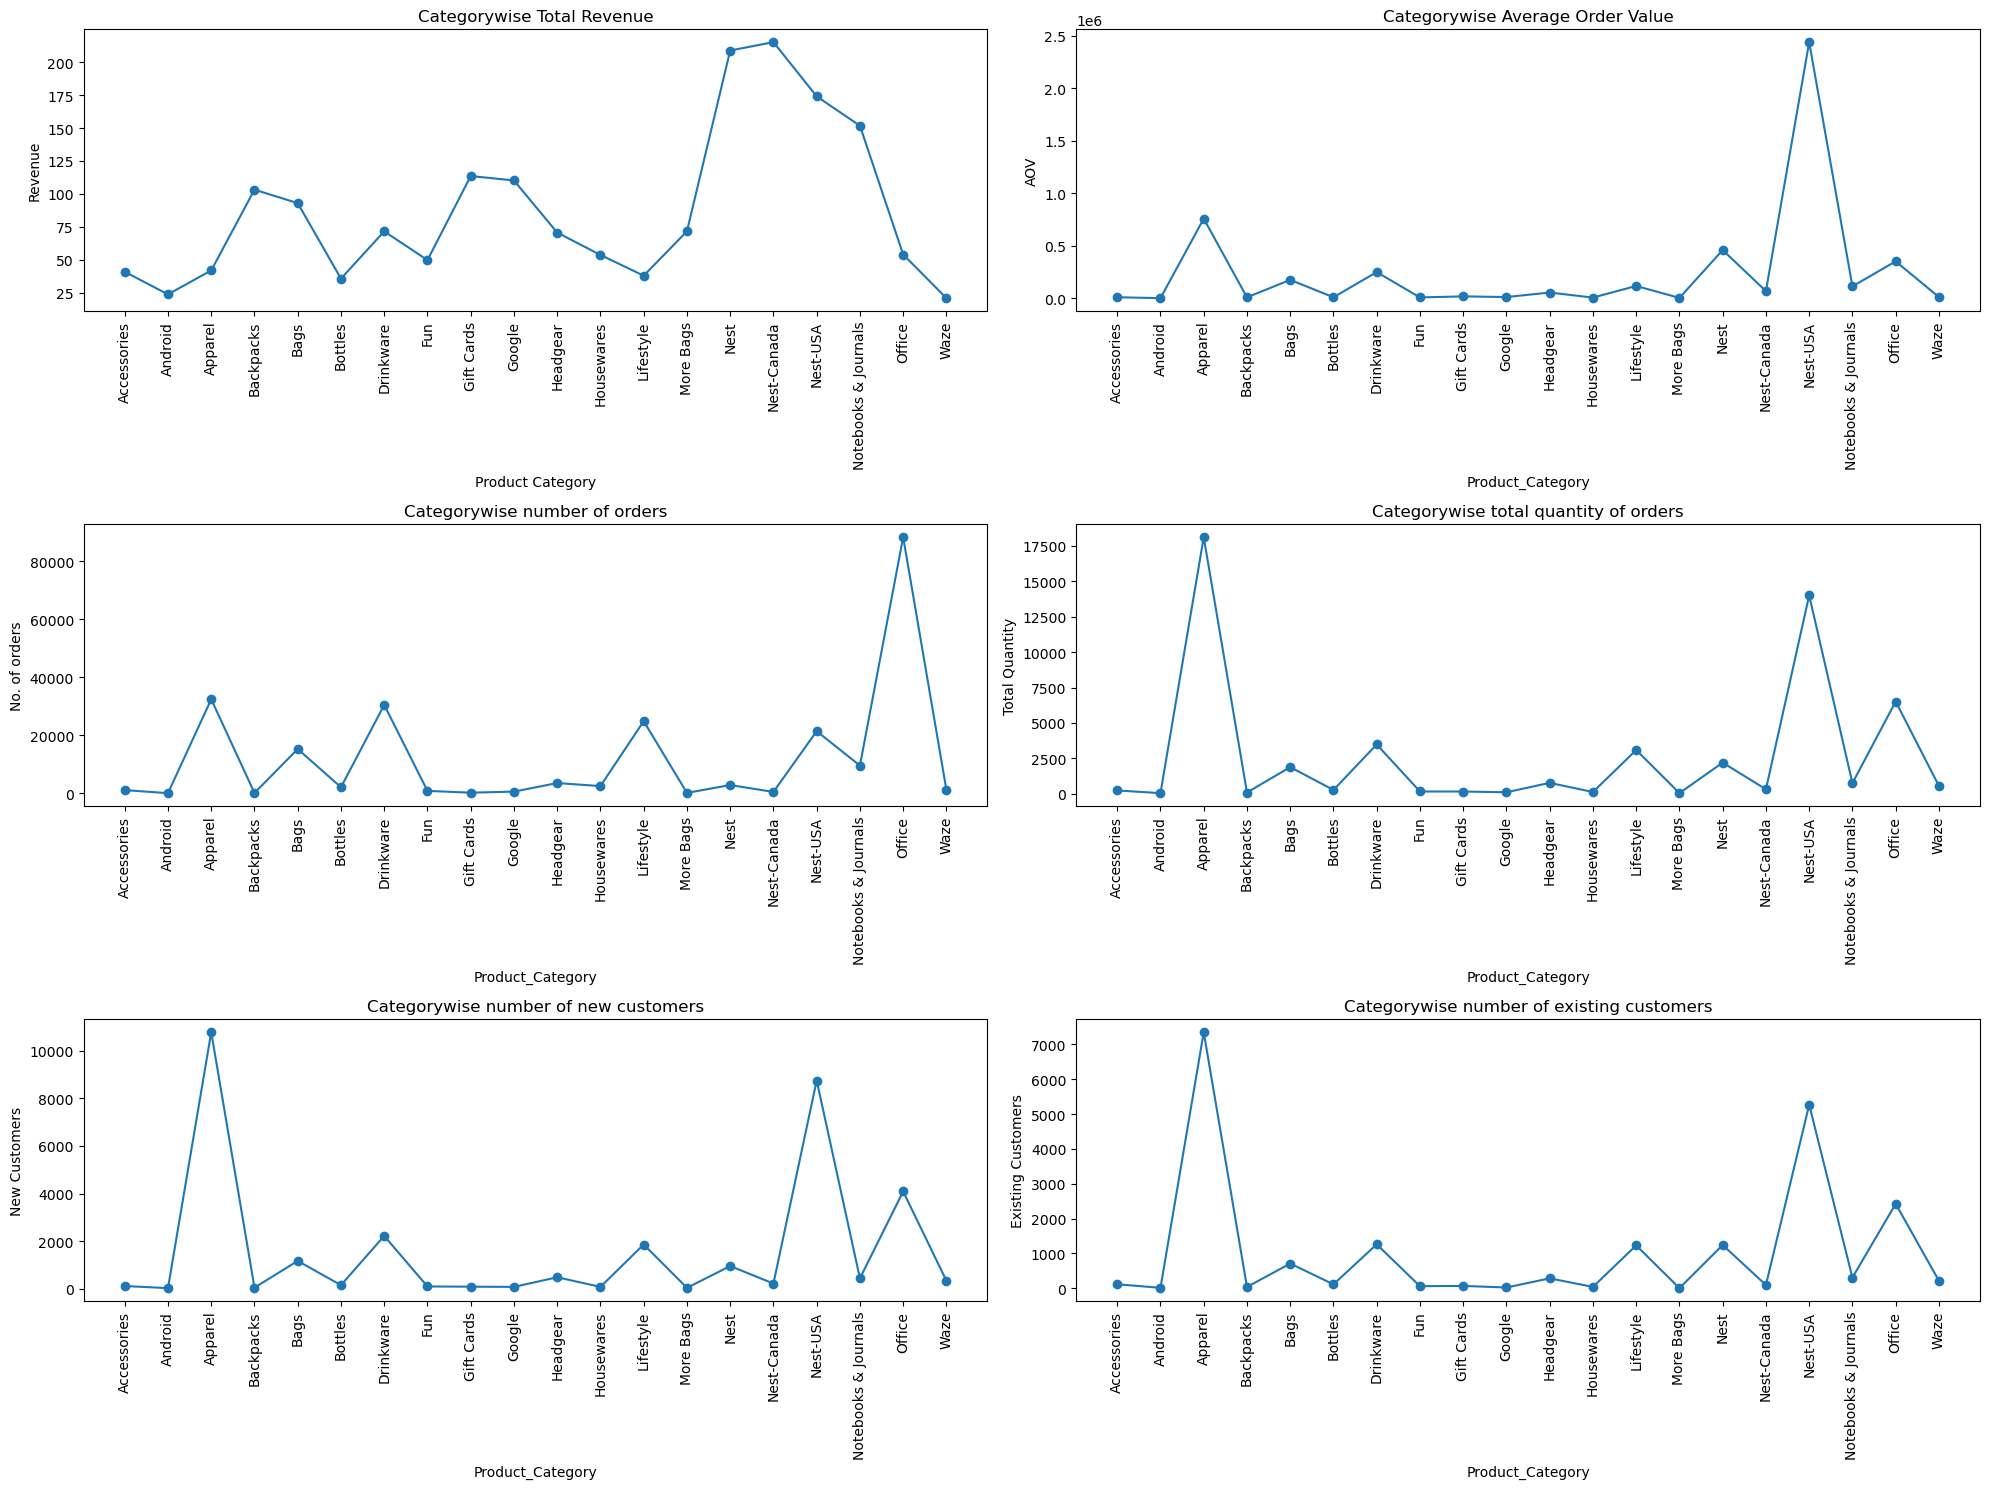

In [58]:
BOLD = '\033[1m'
RESET = '\033[0m'

print(f"{BOLD}The KPIs per product category are as follows:{RESET}\n")

KPI_categorywise = pd.pivot_table(
    Final_Df,
    index='Product_Category',
    values=['Invoice_Value', 'Transaction_ID', 'Quantity'],
    aggfunc={
        'Invoice_Value': ['sum', 'mean'],
        'Transaction_ID': 'count',
        'Quantity': 'sum'
    },
    fill_value=0
)

New_cust_cat = pd.pivot_table(Final_Df.loc[Final_Df['Customer_Type']=='New',:],index = 'Product_Category',values='CustomerID',aggfunc='count').reset_index()

Existing_cust_cat = pd.pivot_table(Final_Df.loc[Final_Df['Customer_Type']=='Existing',:],index = 'Product_Category',values='CustomerID',aggfunc='count').reset_index()

KPI_categorywise.columns = [
    'Total_Revenue',
    'Average_Order_Value',
    'No_of_Orders',
    'Total_Quantity'
]

KPI_categorywise= pd.merge(
    KPI_categorywise,
    New_cust_cat,
    on='Product_Category',
    how='left'
)

KPI_categorywise = pd.merge(
    KPI_categorywise,
    Existing_cust_cat,
    on='Product_Category',
    how='left'
)

KPI_categorywise.columns = ['Product_Category',
    'Total_Revenue',
    'Average_Order_Value',
    'No_of_Orders',
    'Total_Quantity',
    'New_Customers',
    'Existing_Customers'
]
                              

## Visualization

fig,axes  = plt.subplots(3,2,figsize=(20,15))

# 1. Total Revenue
axes[0, 0].plot(
    KPI_categorywise['Product_Category'],
    KPI_categorywise['Total_Revenue'],
    marker='o'
)
axes[0, 0].set_title('Categorywise Total Revenue')
axes[0, 0].set_xlabel('Product Category')
axes[0, 0].set_ylabel('Revenue')

# 2. Average Order Value
axes[0, 1].plot(
    KPI_categorywise['Product_Category'],
    KPI_categorywise['Average_Order_Value'],
    marker='o'
)
axes[0, 1].set_title('Categorywise Average Order Value')
axes[0, 1].set_xlabel('Product_Category')
axes[0, 1].set_ylabel('AOV')

# 3 Total number of orders

axes[1,0].plot(
    KPI_categorywise['Product_Category'],
    KPI_categorywise['No_of_Orders'],
    marker='o'
)
axes[1,0].set_title('Categorywise number of orders')
axes[1,0].set_xlabel('Product_Category')
axes[1,0].set_ylabel('No. of orders')

# 4 Total Quantity
axes[1,1].plot(
    KPI_categorywise['Product_Category'],
    KPI_categorywise['Total_Quantity'],
    marker='o'
)
axes[1,1].set_title('Categorywise total quantity of orders')
axes[1,1].set_xlabel('Product_Category')
axes[1,1].set_ylabel('Total Quantity')

# 5 Category-wise number of new customers

axes[2,0].plot(
    KPI_categorywise['Product_Category'],
    KPI_categorywise['New_Customers'],
    marker='o'
)
axes[2,0].set_title('Categorywise number of new customers')
axes[2,0].set_xlabel('Product_Category')
axes[2,0].set_ylabel('New Customers')

# 6 Category-wise number of existing customers

axes[2,1].plot(
    KPI_categorywise['Product_Category'],
    KPI_categorywise['Existing_Customers'],
    marker='o'
)
axes[2,1].set_title('Categorywise number of existing customers')
axes[2,1].set_xlabel('Product_Category')
axes[2,1].set_ylabel('Existing Customers')

for ax in axes.flat:
    ax.tick_params(axis='x', rotation=90)
    
plt.tight_layout()
plt.show()

In [59]:
Final_Df.Product_Category.unique()

array(['Nest-USA', 'Office', 'Apparel', 'Bags', 'Drinkware', 'Lifestyle',
       'Notebooks & Journals', 'Headgear', 'Waze', 'Fun', 'Nest-Canada',
       'Backpacks', 'Google', 'Bottles', 'Gift Cards', 'More Bags',
       'Housewares', 'Android', 'Accessories', 'Nest'], dtype=object)

 ##### KPIs per month

In [60]:
Final_Df.columns

Index(['CustomerID', 'Transaction_ID', 'Transaction_Date', 'Product_SKU',
       'Product_Description', 'Product_Category', 'Quantity', 'Avg_Price',
       'Delivery_Charges', 'Coupon_Status', 'Transaction_Month', 'Gender',
       'Location', 'Tenure_Months', 'Month', 'Coupon_Code', 'Discount_pct',
       'GST', 'Invoice_Value', 'Acquisition_month', 'Customer_Type',
       'Discount_Applied', 'Week', 'Transaction_Day'],
      dtype='object')

The KPIs per month are as follows:



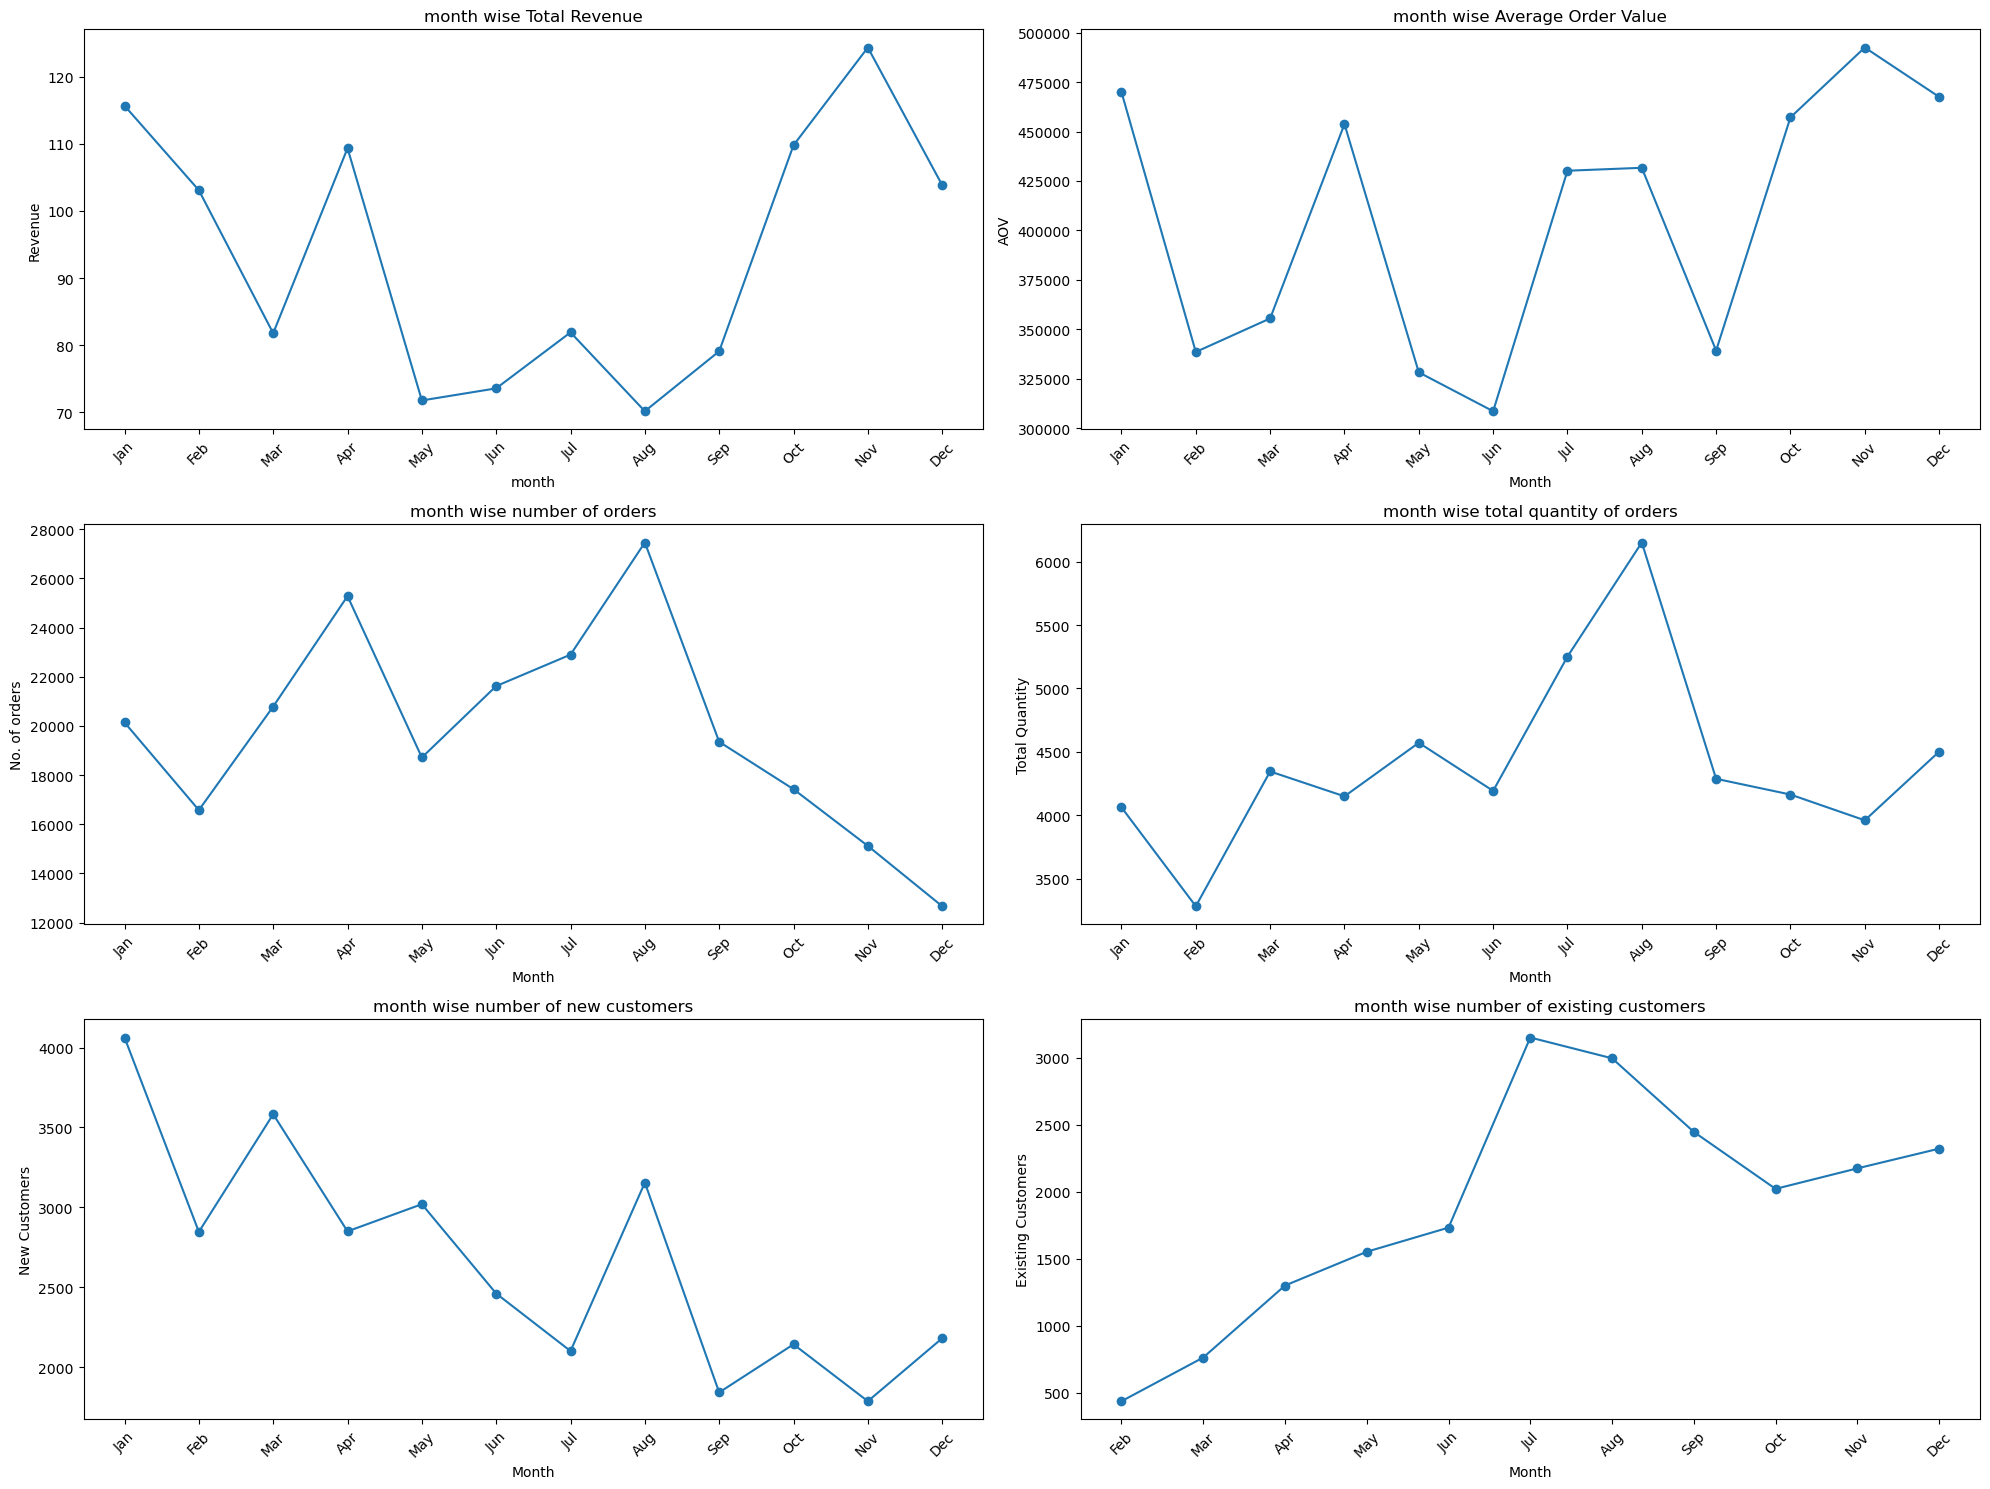

In [61]:
## WORK HERE: Month order need to be reset to jan, Feb, etc. 

month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

BOLD = '\033[1m'
RESET = '\033[0m'

print(f"{BOLD}The KPIs per month are as follows:{RESET}\n")

KPI_monthwise = pd.pivot_table(
    Final_Df,
    index='Month',
    values=['Invoice_Value', 'Transaction_ID', 'Quantity'],
    aggfunc={
        'Invoice_Value': ['sum', 'mean'],
        'Transaction_ID': 'count',
        'Quantity': 'sum'
    },
    fill_value=0
)

New_cust_mon = pd.pivot_table(Final_Df.loc[Final_Df['Customer_Type']=='New',:],index = 'Month',values='CustomerID',aggfunc='count').reset_index()

Existing_cust_mon = pd.pivot_table(Final_Df.loc[Final_Df['Customer_Type']=='Existing',:],index = 'Month',values='CustomerID',aggfunc='count').reset_index()

KPI_monthwise.columns = [
    'Total_Revenue',
    'Average_Order_Value',
    'No_of_Orders',
    'Total_Quantity'
]

KPI_monthwise= pd.merge(
    KPI_monthwise,
    New_cust_mon,
    on='Month',
    how='left'
)

KPI_monthwise = pd.merge(
    KPI_monthwise,
    Existing_cust_mon,
    on='Month',
    how='left'
)

KPI_monthwise.columns = ['Month',
    'Total_Revenue',
    'Average_Order_Value',
    'No_of_Orders',
    'Total_Quantity',
    'New_Customers',
    'Existing_Customers'
]

KPI_monthwise['Month'] = pd.Categorical(
    KPI_monthwise['Month'],
    categories=month_order,
    ordered=True
)

KPI_monthwise = KPI_monthwise.sort_values('Month')

## Visualization

fig,axes  = plt.subplots(3,2,figsize=(20,15))

# 1. Total Revenue
axes[0, 0].plot(
    KPI_monthwise['Month'],
    KPI_monthwise['Total_Revenue'],
    marker='o'
)
axes[0, 0].set_title('month wise Total Revenue')
axes[0, 0].set_xlabel('month')
axes[0, 0].set_ylabel('Revenue')

# 2. Average Order Value
axes[0, 1].plot(
    KPI_monthwise['Month'],
    KPI_monthwise['Average_Order_Value'],
    marker='o'
)
axes[0, 1].set_title('month wise Average Order Value')
axes[0, 1].set_xlabel('Month')
axes[0, 1].set_ylabel('AOV')

# 3 Total number of orders

axes[1,0].plot(
    KPI_monthwise['Month'],
    KPI_monthwise['No_of_Orders'],
    marker='o'
)
axes[1,0].set_title('month wise number of orders')
axes[1,0].set_xlabel('Month')
axes[1,0].set_ylabel('No. of orders')

# 4 Total Quantity
axes[1,1].plot(
    KPI_monthwise['Month'],
    KPI_monthwise['Total_Quantity'],
    marker='o'
)
axes[1,1].set_title('month wise total quantity of orders')
axes[1,1].set_xlabel('Month')
axes[1,1].set_ylabel('Total Quantity')

# 5 Category-wise number of new customers

axes[2,0].plot(
    KPI_monthwise['Month'],
    KPI_monthwise['New_Customers'],
    marker='o'
)
axes[2,0].set_title('month wise number of new customers')
axes[2,0].set_xlabel('Month')
axes[2,0].set_ylabel('New Customers')

# 6 Category-wise number of existing customers

axes[2,1].plot(
    KPI_monthwise['Month'],
    KPI_monthwise['Existing_Customers'],
    marker='o'
)
axes[2,1].set_title('month wise number of existing customers')
axes[2,1].set_xlabel('Month')
axes[2,1].set_ylabel('Existing Customers')

for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)
    
plt.tight_layout()
plt.show()

#### The KPIs per week

The KPIs per week is as follows:



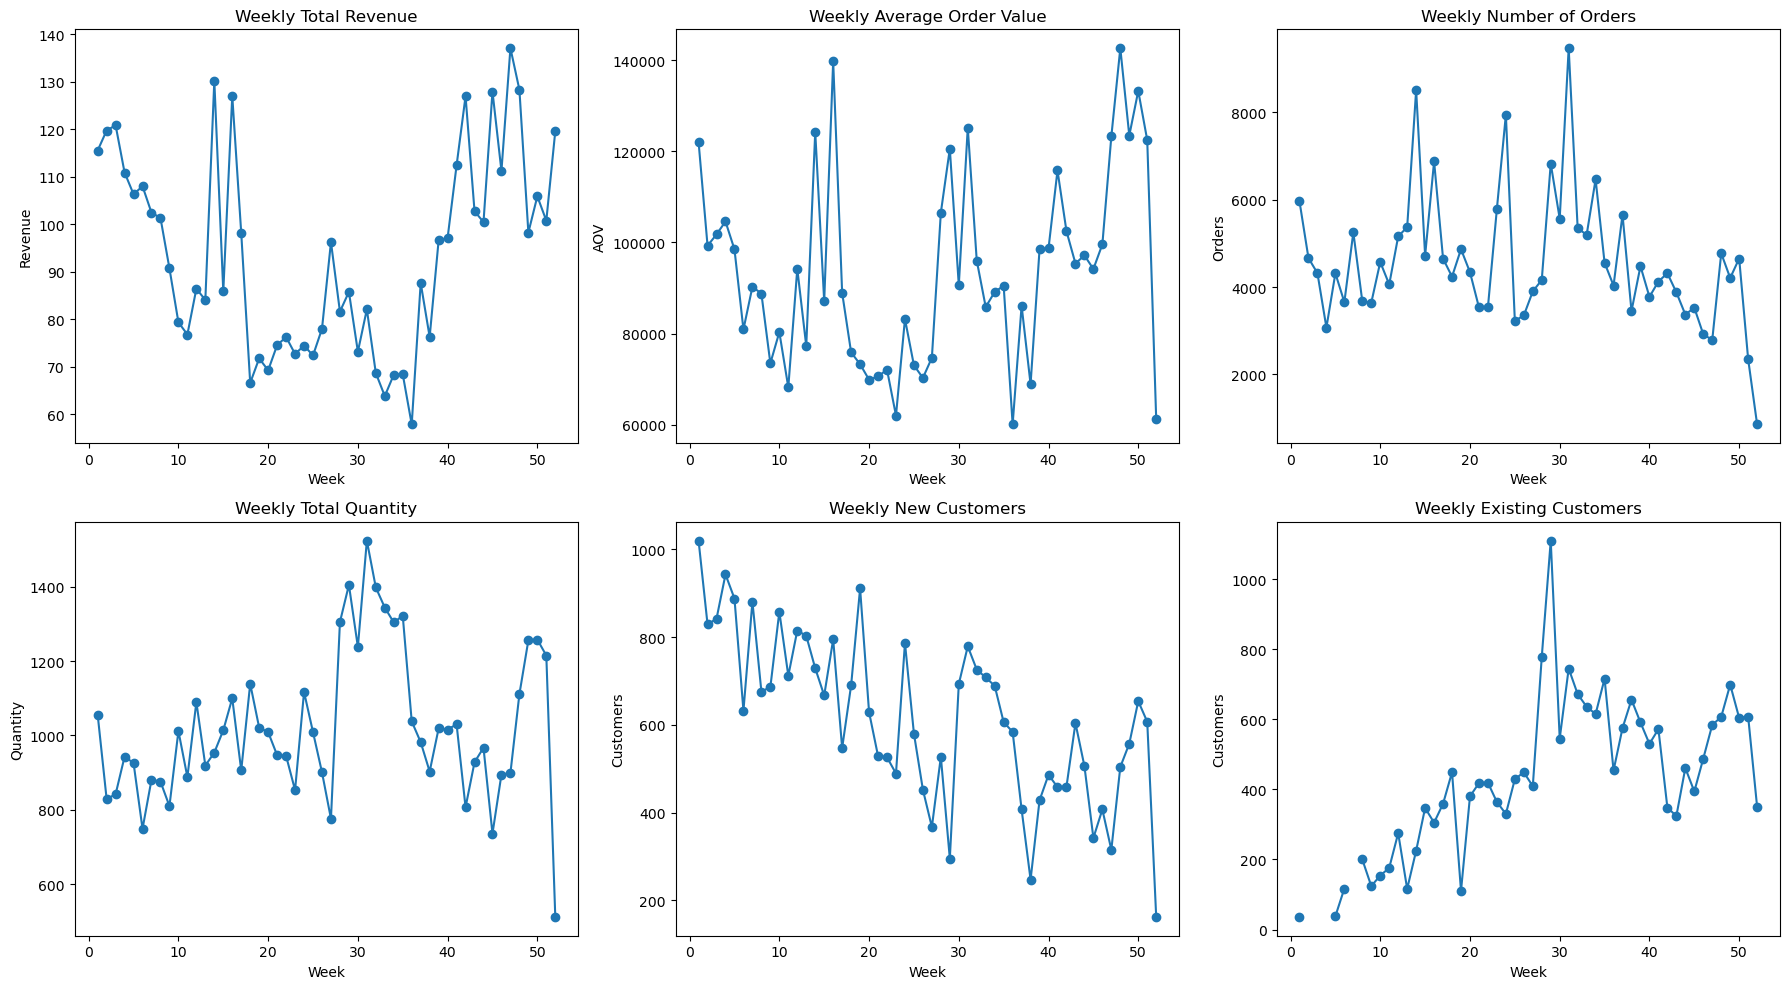

In [62]:
BOLD = '\033[1m'
RESET = '\033[0m'

print(f"{BOLD}The KPIs per week is as follows:{RESET}\n")

KPI_weekwise = pd.pivot_table(
    Final_Df,
    index='Week',
    values=['Invoice_Value', 'Transaction_ID', 'Quantity'],
    aggfunc={
        'Invoice_Value': ['sum', 'mean'],
        'Transaction_ID': 'count',
        'Quantity': 'sum'
    },
    fill_value=0
)

New_cust_wk = pd.pivot_table(Final_Df.loc[Final_Df['Customer_Type']=='New',:],index = 'Week',values='CustomerID',aggfunc='count').reset_index()
# print(New_cust_wk)

Existing_cust_wk = pd.pivot_table(Final_Df.loc[Final_Df['Customer_Type']=='Existing',:],index = 'Week',values='CustomerID',aggfunc='count').reset_index()
# print(Existing_cust_wk)

KPI_weekwise.columns = [
    'Total_Revenue',
    'Average_Order_Value',
    'No_of_Orders',
    'Total_Quantity'
]

KPI_weekwise = pd.merge(
    KPI_weekwise,
    New_cust_wk,
    on='Week',
    how='left'
)

KPI_weekwise = pd.merge(
    KPI_weekwise,
    Existing_cust_wk,
    on='Week',
    how='left'
)

KPI_weekwise.columns = ['Week',
    'Total_Revenue',
    'Average_Order_Value',
    'No_of_Orders',
    'Total_Quantity',
    'New_Customers',
    'Existing_Customers'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Total Revenue
axes[0, 0].plot(
    KPI_weekwise['Week'],
    KPI_weekwise['Total_Revenue'],
    marker='o'
)
axes[0, 0].set_title('Weekly Total Revenue')
axes[0, 0].set_xlabel('Week')
axes[0, 0].set_ylabel('Revenue')

# 2. Average Order Value
axes[0, 1].plot(
    KPI_weekwise['Week'],
    KPI_weekwise['Average_Order_Value'],
    marker='o'
)
axes[0, 1].set_title('Weekly Average Order Value')
axes[0, 1].set_xlabel('Week')
axes[0, 1].set_ylabel('AOV')

# 3. Number of Orders
axes[0, 2].plot(
    KPI_weekwise['Week'],
    KPI_weekwise['No_of_Orders'],
    marker='o'
)
axes[0, 2].set_title('Weekly Number of Orders')
axes[0, 2].set_xlabel('Week')
axes[0, 2].set_ylabel('Orders')

# 4. Total Quantity
axes[1, 0].plot(
    KPI_weekwise['Week'],
    KPI_weekwise['Total_Quantity'],
    marker='o'
)
axes[1, 0].set_title('Weekly Total Quantity')
axes[1, 0].set_xlabel('Week')
axes[1, 0].set_ylabel('Quantity')

# 5. New Customers
axes[1, 1].plot(
    KPI_weekwise['Week'],
    KPI_weekwise['New_Customers'],
    marker='o'
)
axes[1, 1].set_title('Weekly New Customers')
axes[1, 1].set_xlabel('Week')
axes[1, 1].set_ylabel('Customers')

# 6. Existing Customers
axes[1, 2].plot(
    KPI_weekwise['Week'],
    KPI_weekwise['Existing_Customers'],
    marker='o'
)
axes[1, 2].set_title('Weekly Existing Customers')
axes[1, 2].set_xlabel('Week')
axes[1, 2].set_ylabel('Customers')

plt.tight_layout()
plt.show()


#### Fro the above graphs, the following observations can be made regarding weekwise sales:
 - 

In [63]:
Final_Df.head()

,CustomerID,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,Quantity,Avg_Price,Delivery_Charges,Coupon_Status,...,Month,Coupon_Code,Discount_pct,GST,Invoice_Value,Acquisition_month,Customer_Type,Discount_Applied,Week,Transaction_Day
0,17850,16679,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,...,Jan,ELEC10,10.0,0.10,158.6729,Jan,New,Discount,1,Tuesday
1,17850,16680,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,...,Jan,ELEC10,10.0,0.10,158.6729,Jan,New,Discount,1,Tuesday
2,17850,16681,2019-01-01,GGOEGFKQ020399,Google Laptop and Cell Phone Stickers,Office,1,2.05,6.5,Used,...,Jan,OFF10,10.0,0.10,8.5295,Jan,New,Discount,1,Tuesday
3,17850,16682,2019-01-01,GGOEGAAB010516,Google Men's 100% Cotton Short Sleeve Hero Tee...,Apparel,5,17.53,6.5,Not Used,...,Jan,SALE10,10.0,0.18,109.9270,Jan,New,No Discount,1,Tuesday
4,17850,16682,2019-01-01,GGOEGBJL013999,Google Canvas Tote Natural/Navy,Bags,1,16.50,6.5,Used,...,Jan,AIO10,10.0,0.18,24.0230,Jan,New,Discount,1,Tuesday


The KPIs per day of the week are as follows:

  Transaction_Day  Total_Revenue  Average_Order_Value  No_of_Orders  \
1          Monday      82.907009         370096.89009         11983   
5         Tuesday      87.977136         405662.57252         11317   
6       Wednesday      97.073574         862692.85055         39797   
4        Thursday      97.880600         880925.40230         44482   
0          Friday      97.570741         904090.48534         52433   
2        Saturday      87.458167         715145.42971         37965   
3          Sunday      86.191794         734267.88985         40056   

   Total_Quantity  New_Customers  Existing_Customers  
1            4464            166                 106  
5            4611            180                 106  
6            8887            289                 207  
4            9000            285                 202  
0            9266            310                 206  
2            8177            264                 167  


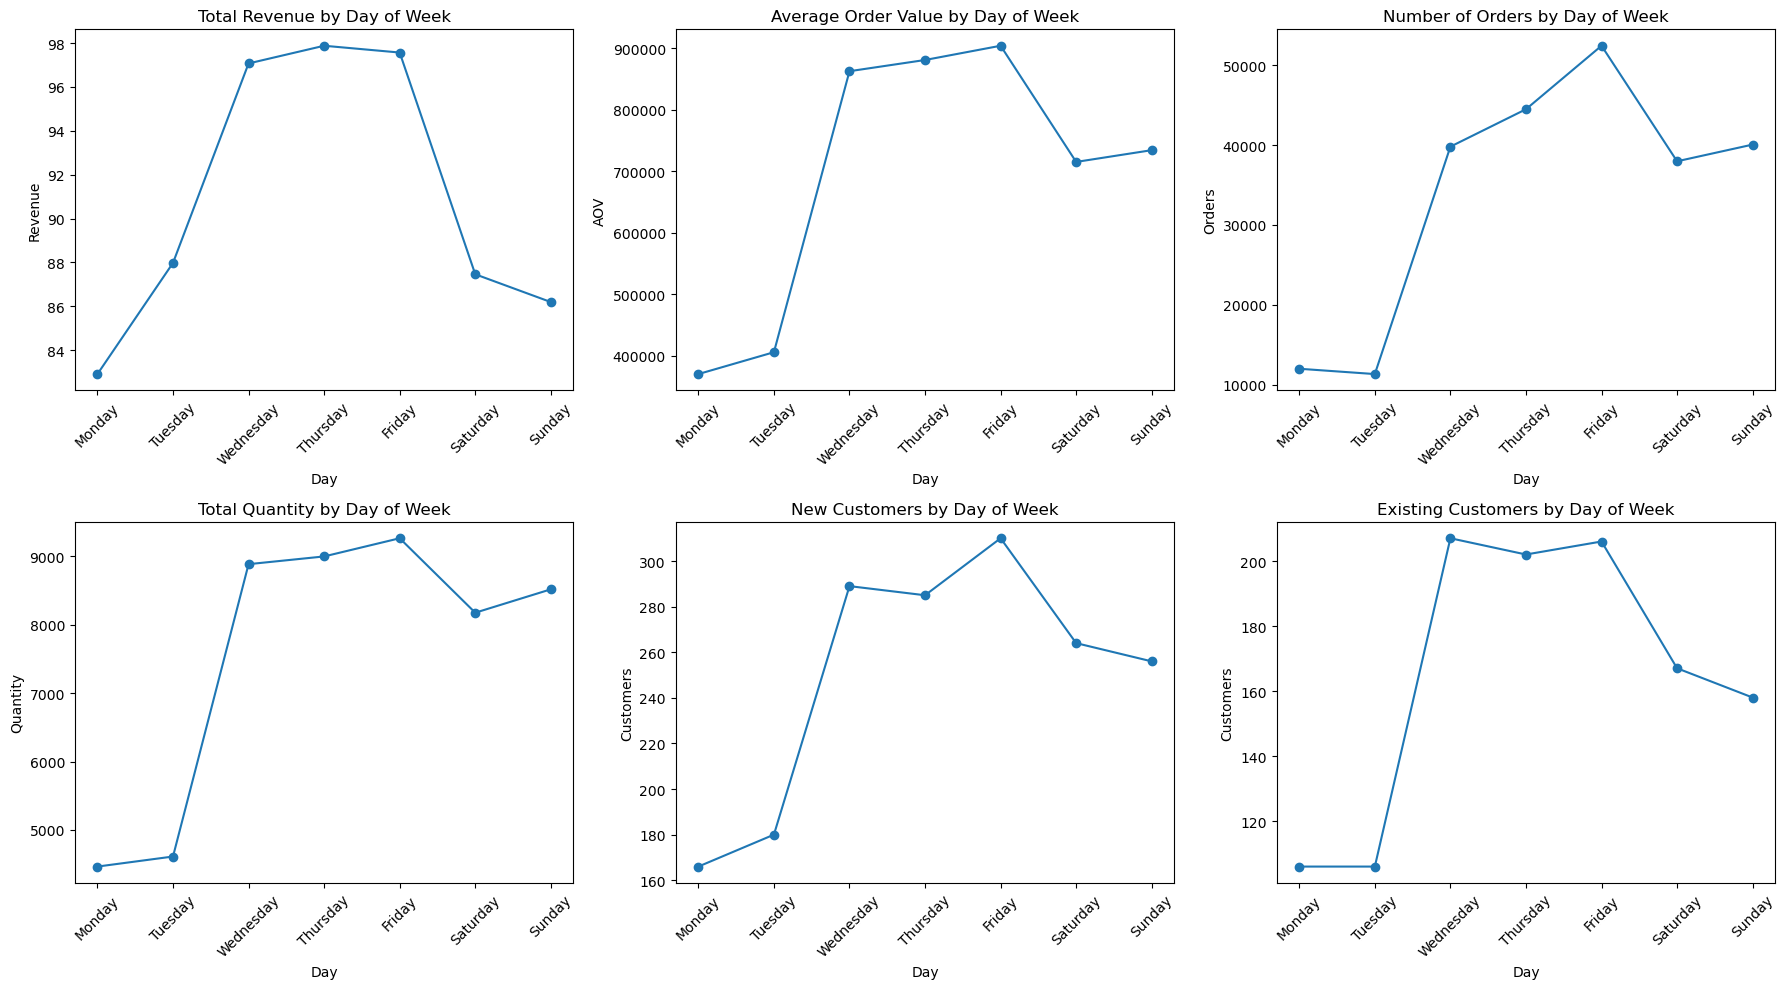

In [64]:
BOLD = '\033[1m'
RESET = '\033[0m'

print(f"{BOLD}The KPIs per day of the week are as follows:{RESET}\n")

# Define correct Monday-Sunday order
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

# Overall KPIs
KPI_daywise = pd.pivot_table(
    Final_Df,
    index='Transaction_Day',
    values=['Invoice_Value', 'Transaction_ID', 'Quantity'],
    aggfunc={
        'Invoice_Value': ['sum', 'mean'],
        'Transaction_ID': 'count',
        'Quantity': 'sum'
    },
    fill_value=0
)

# New customer KPIs
New_cust_day = pd.pivot_table(
    Final_Df.loc[Final_Df['Customer_Type'] == 'New', :],
    index='Transaction_Day',
    values='CustomerID',
    aggfunc='nunique'
).reset_index()

# Existing customer KPIs
Existing_cust_day = pd.pivot_table(
    Final_Df.loc[Final_Df['Customer_Type'] == 'Existing', :],
    index='Transaction_Day',
    values='CustomerID',
    aggfunc='nunique'
).reset_index()

# Rename columns
KPI_daywise.columns = [
    'Total_Revenue',
    'Average_Order_Value',
    'No_of_Orders',
    'Total_Quantity'
]

KPI_daywise = KPI_daywise.reset_index()

# Merge New Customers
KPI_daywise = pd.merge(
    KPI_daywise,
    New_cust_day,
    on='Transaction_Day',
    how='left'
)

# Merge Existing Customers
KPI_daywise = pd.merge(
    KPI_daywise,
    Existing_cust_day,
    on='Transaction_Day',
    how='left'
)

# Rename final columns
KPI_daywise.columns = [
    'Transaction_Day',
    'Total_Revenue',
    'Average_Order_Value',
    'No_of_Orders',
    'Total_Quantity',
    'New_Customers',
    'Existing_Customers'
]

# Arrange Monday → Sunday
KPI_daywise['Transaction_Day'] = pd.Categorical(
    KPI_daywise['Transaction_Day'],
    categories=day_order,
    ordered=True
)

KPI_daywise = KPI_daywise.sort_values('Transaction_Day')

# Display table
print(KPI_daywise)


# ---------------------------------------------------------
# VISUALIZATIONS
# ---------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Total Revenue
axes[0, 0].plot(
    KPI_daywise['Transaction_Day'],
    KPI_daywise['Total_Revenue'],
    marker='o'
)
axes[0, 0].set_title('Total Revenue by Day of Week')
axes[0, 0].set_xlabel('Day')
axes[0, 0].set_ylabel('Revenue')

# 2. Average Order Value
axes[0, 1].plot(
    KPI_daywise['Transaction_Day'],
    KPI_daywise['Average_Order_Value'],
    marker='o'
)
axes[0, 1].set_title('Average Order Value by Day of Week')
axes[0, 1].set_xlabel('Day')
axes[0, 1].set_ylabel('AOV')

# 3. Number of Orders
axes[0, 2].plot(
    KPI_daywise['Transaction_Day'],
    KPI_daywise['No_of_Orders'],
    marker='o'
)
axes[0, 2].set_title('Number of Orders by Day of Week')
axes[0, 2].set_xlabel('Day')
axes[0, 2].set_ylabel('Orders')

# 4. Total Quantity
axes[1, 0].plot(
    KPI_daywise['Transaction_Day'],
    KPI_daywise['Total_Quantity'],
    marker='o'
)
axes[1, 0].set_title('Total Quantity by Day of Week')
axes[1, 0].set_xlabel('Day')
axes[1, 0].set_ylabel('Quantity')

# 5. New Customers
axes[1, 1].plot(
    KPI_daywise['Transaction_Day'],
    KPI_daywise['New_Customers'],
    marker='o'
)
axes[1, 1].set_title('New Customers by Day of Week')
axes[1, 1].set_xlabel('Day')
axes[1, 1].set_ylabel('Customers')

# 6. Existing Customers
axes[1, 2].plot(
    KPI_daywise['Transaction_Day'],
    KPI_daywise['Existing_Customers'],
    marker='o'
)
axes[1, 2].set_title('Existing Customers by Day of Week')
axes[1, 2].set_xlabel('Day')
axes[1, 2].set_ylabel('Customers')

for ax in axes.flat:
    ax.tick_params(axis='x', rotation=45)
    
plt.tight_layout()
plt.show()

### From the above graphs we can make the following observations of sales 
 - The sales KPIs are high between Wednesday to Friday.
 - Number of orders are highest on Fridays
 - Sales KPIs are low on Mondays
 - New and Existing Customers are more during Wednesday - Friday
 - Higest revenue occurs on Thursdays

Overall, it can be observed that more sales can be observed during middle of the week. 

#### 2. Perform Detailed exploratory analysis
        - Understand the trends/seasonality of sales by category, location, month etc…

From the visualizations of the KPIs above, the following observations can be made:


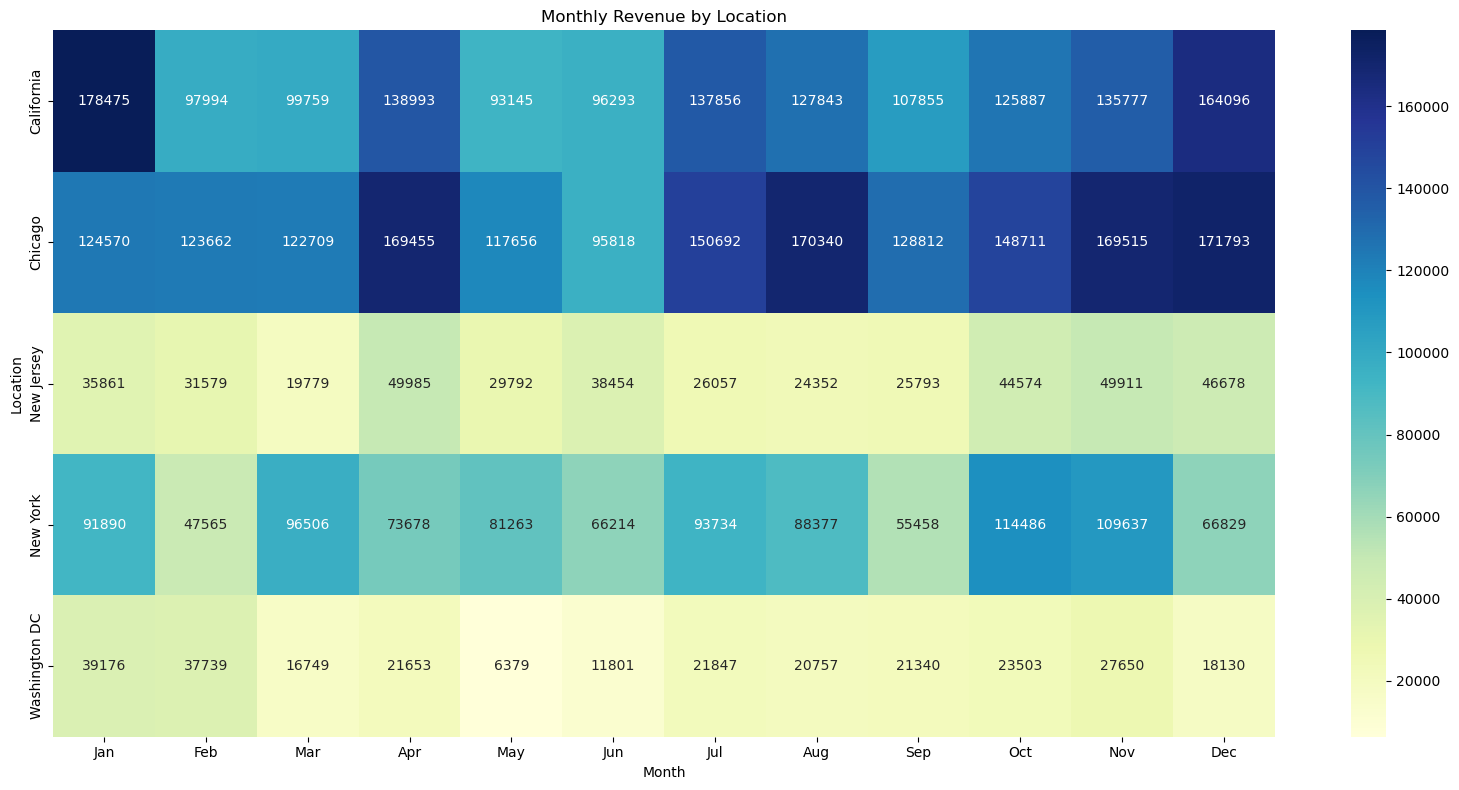

In [65]:
Location_Month_Revenue = pd.pivot_table(
    Final_Df,
    index='Location',
    columns='Month',
    values='Invoice_Value',
    aggfunc='sum',
    fill_value=0
)

Location_Month_Revenue = Location_Month_Revenue.reindex(
    columns=month_order
)

plt.figure(figsize=(16, 8))

sns.heatmap(
    Location_Month_Revenue,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title('Monthly Revenue by Location')
plt.xlabel('Month')
plt.ylabel('Location')
plt.tight_layout()
plt.show()

#### From the above heatmap of month vs city, the following observations can be made
- California and Chicago see high sales compared to all other cities
- California has the highest sales in the January and December
- Chicago has the highest sales in December, followed by November
- The overall lowest sales is seen in Washington DC in the month of May
- The overall highest sales occur in California in January
- Washington DC and New Jersey see low to moderate sales throughout the area.
- The highest sales in New Jersey occur in the month of March
- The highest sales in Washington DC occur in them month of January followed by February.

#### Calculate the Revenue, Marketing spend, percentage of marketing spend out of revenue, Tax, percentage of delivery charges by month.

In [66]:
Marketing_Spend_DF.head()

,Date,Offline_Spend,Online_Spend
0,2019-01-01,4500,2424.50
1,2019-01-02,4500,3480.36
2,2019-01-03,4500,1576.38
3,2019-01-04,4500,2928.55
4,2019-01-05,4500,4055.30


In [67]:
Marketing_Spend_DF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           365 non-null    datetime64[ns]
 1   Offline_Spend  365 non-null    int64         
 2   Online_Spend   365 non-null    float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 8.7 KB


In [68]:
Tax_Amount_DF.head()

,Product_Category,GST
0,Nest-USA,0.10
1,Office,0.10
2,Apparel,0.18
3,Bags,0.18
4,Drinkware,0.18


In [69]:
Final_Df.head()

,CustomerID,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,Quantity,Avg_Price,Delivery_Charges,Coupon_Status,...,Month,Coupon_Code,Discount_pct,GST,Invoice_Value,Acquisition_month,Customer_Type,Discount_Applied,Week,Transaction_Day
0,17850,16679,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,...,Jan,ELEC10,10.0,0.10,158.6729,Jan,New,Discount,1,Tuesday
1,17850,16680,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,...,Jan,ELEC10,10.0,0.10,158.6729,Jan,New,Discount,1,Tuesday
2,17850,16681,2019-01-01,GGOEGFKQ020399,Google Laptop and Cell Phone Stickers,Office,1,2.05,6.5,Used,...,Jan,OFF10,10.0,0.10,8.5295,Jan,New,Discount,1,Tuesday
3,17850,16682,2019-01-01,GGOEGAAB010516,Google Men's 100% Cotton Short Sleeve Hero Tee...,Apparel,5,17.53,6.5,Not Used,...,Jan,SALE10,10.0,0.18,109.9270,Jan,New,No Discount,1,Tuesday
4,17850,16682,2019-01-01,GGOEGBJL013999,Google Canvas Tote Natural/Navy,Bags,1,16.50,6.5,Used,...,Jan,AIO10,10.0,0.18,24.0230,Jan,New,Discount,1,Tuesday


### Calculate the Revenue, Marketing spend, percentage of marketing spend out of revenue, Tax, percentage of delivery charges by month.

In [75]:
Marketing_Spend_DF['Month'] = Marketing_Spend_DF['Date'].dt.strftime('%b')
print(Marketing_Spend_DF)

          Date  Offline_Spend  Online_Spend Month
0   2019-01-01           4500       2424.50   Jan
1   2019-01-02           4500       3480.36   Jan
2   2019-01-03           4500       1576.38   Jan
3   2019-01-04           4500       2928.55   Jan
4   2019-01-05           4500       4055.30   Jan
..         ...            ...           ...   ...
360 2019-12-27           4000       3396.87   Dec
361 2019-12-28           4000       3246.84   Dec
362 2019-12-29           4000       2546.58   Dec
363 2019-12-30           4000        674.31   Dec
364 2019-12-31           4000       2058.75   Dec

[365 rows x 4 columns]


In [76]:
Marketing_Spend_monthly = pd.pivot_table(Marketing_Spend_DF,index='Month',values = ['Offline_Spend','Online_Spend'],aggfunc='sum').reset_index()
print(Marketing_Spend_monthly)

   Month  Offline_Spend  Online_Spend
0    Apr          96000      61026.83
1    Aug          85500      57404.15
2    Dec         122000      76648.75
3    Feb          81300      55807.92
4    Jan          96600      58328.95
5    Jul          67500      52717.85
6    Jun          80500      53818.14
7    Mar          73500      48750.09
8    May          65500      52759.64
9    Nov          93000      68144.96
10   Oct          93500      57724.65
11   Sep          83000      52514.54


In [77]:
Revenue_monthly = pd.pivot_table(Final_Df,index = 'Month', values = ['Invoice_Value','Delivery_Charges'],aggfunc='sum').reset_index()
print(Revenue_monthly)

   Month  Delivery_Charges  Invoice_Value
0    Apr          41481.74   453764.24058
1    Aug          61099.57   431668.06364
2    Dec          37881.99   467526.63756
3    Feb          49216.60   338539.79210
4    Jan          59242.32   469970.07337
5    Jul          48723.93   430185.96433
6    Jun          37513.58   308579.58305
7    Mar          60799.94   355502.36221
8    May          41396.17   328236.13672
9    Nov          32311.93   492489.47362
10   Oct          45961.88   457161.09152
11   Sep          41005.42   339258.10166


In [78]:
Final_Df_wth_marketing = pd.merge(Revenue_monthly, Marketing_Spend_monthly, on= 'Month', how = 'left')
Final_Df_wth_marketing.rename(columns= {'Invoice_Value':'Revenue'},inplace=True)
Final_Df_wth_marketing['Marketing_spend_total'] = Final_Df_wth_marketing['Offline_Spend']+Final_Df_wth_marketing['Online_Spend']
print(Final_Df_wth_marketing)

   Month  Delivery_Charges       Revenue  Offline_Spend  Online_Spend  \
0    Apr          41481.74  453764.24058          96000      61026.83   
1    Aug          61099.57  431668.06364          85500      57404.15   
2    Dec          37881.99  467526.63756         122000      76648.75   
3    Feb          49216.60  338539.79210          81300      55807.92   
4    Jan          59242.32  469970.07337          96600      58328.95   
5    Jul          48723.93  430185.96433          67500      52717.85   
6    Jun          37513.58  308579.58305          80500      53818.14   
7    Mar          60799.94  355502.36221          73500      48750.09   
8    May          41396.17  328236.13672          65500      52759.64   
9    Nov          32311.93  492489.47362          93000      68144.96   
10   Oct          45961.88  457161.09152          93500      57724.65   
11   Sep          41005.42  339258.10166          83000      52514.54   

    Marketing_spend_total  
0               157026

In [79]:
Final_Df_wth_marketing['% Delivery_charges'] = Final_Df_wth_marketing['Delivery_Charges']/Final_Df_wth_marketing['Revenue']*100
Final_Df_wth_marketing['% Marketing_spend'] = Final_Df_wth_marketing['Marketing_spend_total']/Final_Df_wth_marketing['Revenue']*100

In [80]:
Final_Df_wth_marketing

,Month,Delivery_Charges,Revenue,Offline_Spend,Online_Spend,Marketing_spend_total,% Delivery_charges,% Marketing_spend
0,Apr,41481.74,453764.24058,96000,61026.83,157026.83,9.141694,34.605378
1,Aug,61099.57,431668.06364,85500,57404.15,142904.15,14.154295,33.105101
2,Dec,37881.99,467526.63756,122000,76648.75,198648.75,8.102638,42.489290
3,Feb,49216.60,338539.79210,81300,55807.92,137107.92,14.537907,40.499794
4,Jan,59242.32,469970.07337,96600,58328.95,154928.95,12.605552,32.965705
5,Jul,48723.93,430185.96433,67500,52717.85,120217.85,11.326248,27.945554
6,Jun,37513.58,308579.58305,80500,53818.14,134318.14,12.156857,43.527877
7,Mar,60799.94,355502.36221,73500,48750.09,122250.09,17.102542,34.387982
8,May,41396.17,328236.13672,65500,52759.64,118259.64,12.611704,36.028830
9,Nov,32311.93,492489.47362,93000,68144.96,161144.96,6.560938,32.720488


In [81]:
Final_Df_wth_marketing['Month'] = pd.Categorical(
    Final_Df_wth_marketing['Month'],
    categories=month_order,
    ordered=True
)

Final_Df_wth_marketing = Final_Df_wth_marketing.sort_values('Month')

In [82]:
Final_Df_wth_marketing

,Month,Delivery_Charges,Revenue,Offline_Spend,Online_Spend,Marketing_spend_total,% Delivery_charges,% Marketing_spend
4,Jan,59242.32,469970.07337,96600,58328.95,154928.95,12.605552,32.965705
3,Feb,49216.60,338539.79210,81300,55807.92,137107.92,14.537907,40.499794
7,Mar,60799.94,355502.36221,73500,48750.09,122250.09,17.102542,34.387982
0,Apr,41481.74,453764.24058,96000,61026.83,157026.83,9.141694,34.605378
8,May,41396.17,328236.13672,65500,52759.64,118259.64,12.611704,36.028830
6,Jun,37513.58,308579.58305,80500,53818.14,134318.14,12.156857,43.527877
5,Jul,48723.93,430185.96433,67500,52717.85,120217.85,11.326248,27.945554
1,Aug,61099.57,431668.06364,85500,57404.15,142904.15,14.154295,33.105101
11,Sep,41005.42,339258.10166,83000,52514.54,135514.54,12.086792,39.944378
10,Oct,45961.88,457161.09152,93500,57724.65,151224.65,10.053760,33.079073


#### The percentage of Marketing Spends and delivery charges are calculated above. The highest marketing spend was in the month of June

### How marketing spend is impacting on revenue?

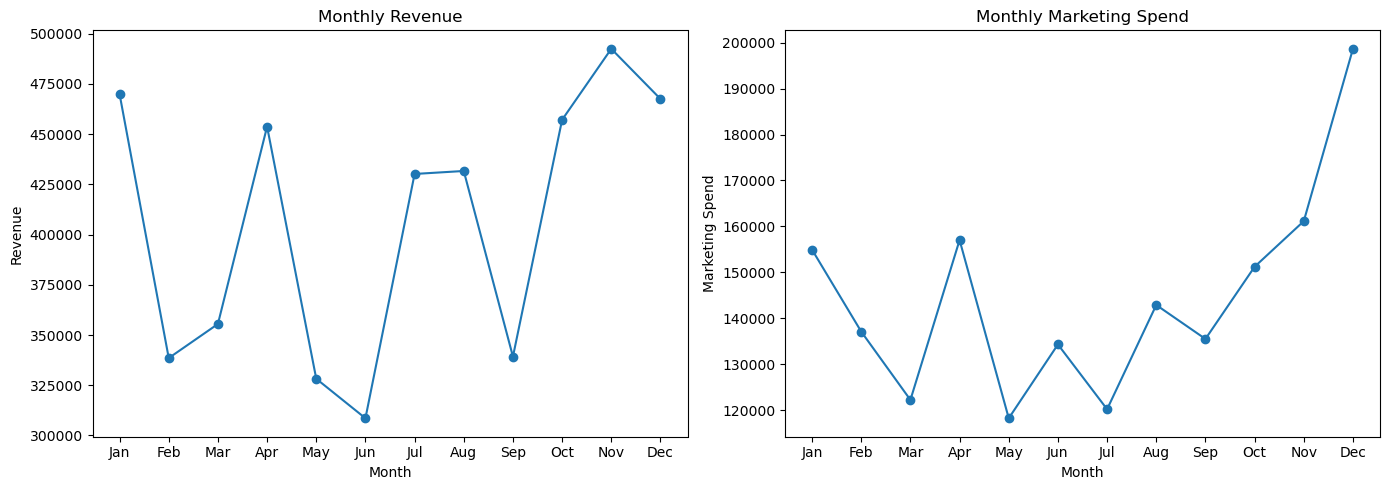

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    Final_Df_wth_marketing['Month'],
    Final_Df_wth_marketing['Revenue'],
    marker='o'
)
axes[0].set_title('Monthly Revenue')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Revenue')

axes[1].plot(
    Final_Df_wth_marketing['Month'],
    Final_Df_wth_marketing['Marketing_spend_total'],
    marker='o'
)
axes[1].set_title('Monthly Marketing Spend')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Marketing Spend')

plt.tight_layout()
plt.show()

In [84]:
Final_Df_wth_marketing[
    ['Revenue', 'Marketing_spend_total']
].corr()

,Revenue,Marketing_spend_total
Revenue,1.000000,0.671152
Marketing_spend_total,0.671152,1.000000


#### Marketing spend and revenue show a positive correlation of 0.67, indicating a moderately strong positive association between the two variables. This suggests that higher marketing expenditure tends to coincide with higher revenue. However, correlation does not establish causation, and other factors such as seasonality, product category, discounts, and customer demand may also contribute to changes in revenue.

### Which product appeared the most in the transactions?

In [85]:
Product_most = pd.pivot_table(Final_Df,index = 'Product_Description',values = 'Transaction_ID',aggfunc='count').reset_index()
Product_most.rename(columns = {'Transaction_ID':'No_of_Transactions'},inplace=True)
Product_most.sort_values(by ='No_of_Transactions',ascending=False,inplace=True)


In [86]:
Product_most.reset_index(drop = True)

,Product_Description,No_of_Transactions
0,Nest Learning Thermostat 3rd Gen-USA - Stainle...,3511
1,Nest Cam Outdoor Security Camera - USA,3328
2,Nest Cam Indoor Security Camera - USA,3230
3,Google Sunglasses,1523
4,Nest Protect Smoke + CO White Battery Alarm-USA,1361
...,...,...
399,Google Tee Red,2
400,Google Large Standard Journal Grey,1
401,Google Women's Colorblock Tee White,1
402,Android Women's Short Sleeve Tri-blend Badge T...,1


In [93]:
type(Product_most)

pandas.core.frame.DataFrame

In [87]:
print(f"The product mostly ordered in the transactions are:{Product_most['Product_Description'].iloc[0]}")

The product mostly ordered in the transactions are:Nest Learning Thermostat 3rd Gen-USA - Stainless Steel


### Which product was purchased mostly based on the quantity?

In [94]:
Product_high_Qty = pd.pivot_table(Final_Df,index='Product_Description',values = 'Quantity',aggfunc='sum').reset_index()

In [96]:
Product_high_Qty.sort_values(by = 'Quantity',ascending=False,inplace=True)
print(f" The product ordered highest in quantity is: {Product_high_Qty.Product_Description.iloc[0]} and the order quantity is:{Product_high_Qty.Quantity.iloc[0]}")

 The product ordered highest in quantity is: Maze Pen and the order quantity is:16234


## 3. Performing Customer Segmentation

In [97]:
Final_Df.head()

,CustomerID,Transaction_ID,Transaction_Date,Product_SKU,Product_Description,Product_Category,Quantity,Avg_Price,Delivery_Charges,Coupon_Status,...,Month,Coupon_Code,Discount_pct,GST,Invoice_Value,Acquisition_month,Customer_Type,Discount_Applied,Week,Transaction_Day
0,17850,16679,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,...,Jan,ELEC10,10.0,0.10,158.6729,Jan,New,Discount,1,Tuesday
1,17850,16680,2019-01-01,GGOENEBJ079499,Nest Learning Thermostat 3rd Gen-USA - Stainle...,Nest-USA,1,153.71,6.5,Used,...,Jan,ELEC10,10.0,0.10,158.6729,Jan,New,Discount,1,Tuesday
2,17850,16681,2019-01-01,GGOEGFKQ020399,Google Laptop and Cell Phone Stickers,Office,1,2.05,6.5,Used,...,Jan,OFF10,10.0,0.10,8.5295,Jan,New,Discount,1,Tuesday
3,17850,16682,2019-01-01,GGOEGAAB010516,Google Men's 100% Cotton Short Sleeve Hero Tee...,Apparel,5,17.53,6.5,Not Used,...,Jan,SALE10,10.0,0.18,109.9270,Jan,New,No Discount,1,Tuesday
4,17850,16682,2019-01-01,GGOEGBJL013999,Google Canvas Tote Natural/Navy,Bags,1,16.50,6.5,Used,...,Jan,AIO10,10.0,0.18,24.0230,Jan,New,Discount,1,Tuesday


In [98]:
Final_Df['Transaction_Date'] = pd.to_datetime(
    Final_Df['Transaction_Date']
)

reference_date = Final_Df['Transaction_Date'].max() + pd.Timedelta(days=1)

print(reference_date)

2020-01-01 00:00:00


In [99]:
RFM = Final_Df.groupby('CustomerID').agg(
    Recency=('Transaction_Date',
             lambda x: (reference_date - x.max()).days),

    Frequency=('Transaction_ID',
                'nunique'),

    Monetary=('Invoice_Value',
              'sum')
).reset_index()


In [100]:
RFM

,CustomerID,Recency,Frequency,Monetary
0,12346,108,1,174.98174
1,12347,60,31,13817.90564
2,12348,74,8,1506.52466
3,12350,18,11,1296.64918
4,12356,108,13,1861.61514
...,...,...,...,...
1463,18259,271,3,813.48458
1464,18260,88,19,2644.88407
1465,18269,195,2,157.54774
1466,18277,70,1,333.80000


In [101]:
RFM['R_Score'] = pd.qcut(
    RFM['Recency'],
    5,
    labels=[5, 4, 3, 2, 1]
)

RFM['F_Score'] = pd.qcut(
    RFM['Frequency'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

RFM['M_Score'] = pd.qcut(
    RFM['Monetary'].rank(method='first'),
    5,
    labels=[1, 2, 3, 4, 5]
)

In [102]:
RFM['RFM_Score'] = (
    RFM['R_Score'].astype(int) +
    RFM['F_Score'].astype(int) +
    RFM['M_Score'].astype(int)
)

In [103]:
RFM.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,108,1,174.98174,3,1,1,5
1,12347,60,31,13817.90564,4,5,5,14
2,12348,74,8,1506.52466,4,2,3,9
3,12350,18,11,1296.64918,5,3,3,11
4,12356,108,13,1861.61514,3,3,3,9


In [104]:
RFM.RFM_Score.max()

15

In [105]:
RFM.RFM_Score.min()

3

In [106]:
bins = [3, 6, 9, 12, 15]
labels = [
    'Standard',
    'Silver',
    'Gold',
    'Premium'
]

RFM['Customer_Segment'] = pd.cut(
    RFM['RFM_Score'],
    bins=bins,
    labels=labels
)

In [107]:
RFM


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,12346,108,1,174.98174,3,1,1,5,Standard
1,12347,60,31,13817.90564,4,5,5,14,Premium
2,12348,74,8,1506.52466,4,2,3,9,Silver
3,12350,18,11,1296.64918,5,3,3,11,Gold
4,12356,108,13,1861.61514,3,3,3,9,Silver
...,...,...,...,...,...,...,...,...,...
1463,18259,271,3,813.48458,1,1,2,4,Standard
1464,18260,88,19,2644.88407,4,4,4,12,Gold
1465,18269,195,2,157.54774,2,1,1,4,Standard
1466,18277,70,1,333.80000,4,1,1,6,Standard


### Scientific (Using K-Means) & Understand the profiles. Define strategy for each segment.

In [108]:
Final_Df.columns

Index(['CustomerID', 'Transaction_ID', 'Transaction_Date', 'Product_SKU',
       'Product_Description', 'Product_Category', 'Quantity', 'Avg_Price',
       'Delivery_Charges', 'Coupon_Status', 'Transaction_Month', 'Gender',
       'Location', 'Tenure_Months', 'Month', 'Coupon_Code', 'Discount_pct',
       'GST', 'Invoice_Value', 'Acquisition_month', 'Customer_Type',
       'Discount_Applied', 'Week', 'Transaction_Day'],
      dtype='object')

##### Since, the K-Means clustering should be performed on customer-level numerical behavioural features, a Customer level data frame Customer_Data is ceated as below

In [121]:
Customer_Data = Final_Df.groupby('CustomerID').agg(
    Total_Revenue=('Invoice_Value', 'sum'),
    No_of_Orders=('Transaction_ID', 'nunique'),
    Total_Quantity=('Quantity', 'sum'),
    Average_Order_Value=('Invoice_Value', 'mean'),
    Last_Purchase=('Transaction_Date', 'max')
).reset_index()

# Calculate Recency
Customer_Data['Recency'] = (
    reference_date - Customer_Data['Last_Purchase']
).dt.days

Customer_Data.drop(columns='Last_Purchase', inplace=True)

Customer_Data

,CustomerID,Total_Revenue,No_of_Orders,Total_Quantity,Average_Order_Value,Recency
0,12346,174.98174,1,3,87.490870,108
1,12347,13817.90564,31,342,230.298427,60
2,12348,1506.52466,8,209,65.501072,74
3,12350,1296.64918,11,21,76.273481,18
4,12356,1861.61514,13,56,51.711532,108
...,...,...,...,...,...,...
1463,18259,813.48458,3,46,116.212083,271
1464,18260,2644.88407,19,141,66.122102,88
1465,18269,157.54774,2,10,19.693468,195
1466,18277,333.80000,1,2,333.800000,70


In [124]:
Customer_Data.columns

Index(['CustomerID', 'Total_Revenue', 'No_of_Orders', 'Total_Quantity',
       'Average_Order_Value', 'Recency'],
      dtype='object')

In [125]:
### Defining features for K means clustering

Features = ['Total_Revenue', 'No_of_Orders', 'Total_Quantity', 'Average_Order_Value', 'Recency']

X = Customer_Data[Features]

In [128]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

C:\Users\Chethanasrao\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\Users\Chethanasrao\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\Users\Chethanasrao\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\Users\Chethanasrao\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to 

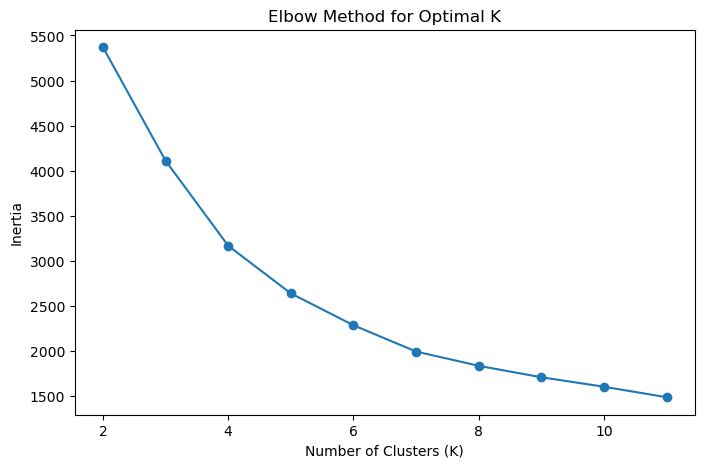

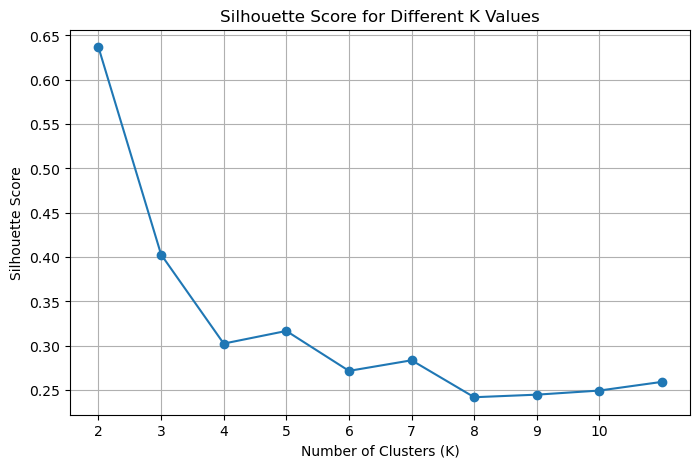

In [137]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_scores = []

K_clusters = range( 2,12)

for i in K_clusters:

    kmeans = KMeans(n_clusters= i, random_state=42,n_init=10)
    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)
    Labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, Labels)
    silhouette_scores.append(score)

plt.figure(figsize= (8,5))

plt.plot(K_clusters, inertia, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')

plt.show()

plt.figure(figsize= (8,5))
plt.plot(K_clusters, silhouette_scores, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different K Values')

plt.xticks(range(2, 11))
plt.grid(True)
plt.show()